# Data visualization

We examine prison population, overcrowding, legal status, demographics and convicted IPC counts. We begin with the findings most relevant to prison-system conditions, then examine detailed crime-head patterns and distributional relationships.

Each analysis cell below prepares its plotting data, creates a Matplotlib or Seaborn figure, and renders it directly. The same figure is saved at 300 dpi for the report. Run all cells from the top to reproduce the figures; saved PNG files are outputs, not inputs.

We use our validated data, single-year rankings and fixed-coverage trends. Counts describe aggregated historical prison records, not individual outcomes or population crime rates. See the [visualization report](../report/visualization.md) for source definitions and limitations.

## Load data and configure plotting

In [1]:
from pathlib import Path
import sys
import os
import json
import math

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", "/tmp/prison-mpl")

%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from src.preprocessing.selection import load_descriptive_view

sns.set_theme(style="whitegrid")
tables = ROOT / "results/tables/descriptive"
output = ROOT / "results/plots"
audit = ROOT / "results/tables/visualization"
output.mkdir(parents=True, exist_ok=True)
audit.mkdir(parents=True, exist_ok=True)
root = ROOT
latest = pd.read_csv(tables / "latest_state_snapshot.csv")
panel = pd.read_csv(tables / "state_year_totals.csv")
profiles = pd.read_csv(ROOT / "data/processed/transformed/profile_features.csv")
year = pd.read_csv(tables / "year_summary_balanced.csv")
demo = pd.read_csv(tables / "demographic_year.csv")
statuses = pd.read_csv(tables / "demographic_status_year.csv")
latest_year = int(latest.year.max())
records = []

# Save each figure for the report and render the figure created in its cell.
def save(name, kind, source, reason, inference):
    plt.tight_layout()
    plt.savefig(output / (name + '.png'), dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()
    records.append(dict(file=name + '.png', kind=kind, source=source, suitability=reason, inference=inference))

def finish(name, kind, data, inference, reason, source):
    plt.tight_layout()
    plt.savefig(output / (name + '.png'), dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()
    data.to_csv(audit / (name + '.csv'), index=False)
    records.append(dict(file=name + '.png', kind=kind, source=source, plot_data='results/tables/visualization/' + name + '.csv', suitability=reason, inference=inference))

## Largest reported prison populations

Compare jurisdiction counts.

Source: `latest_state_snapshot.csv`.

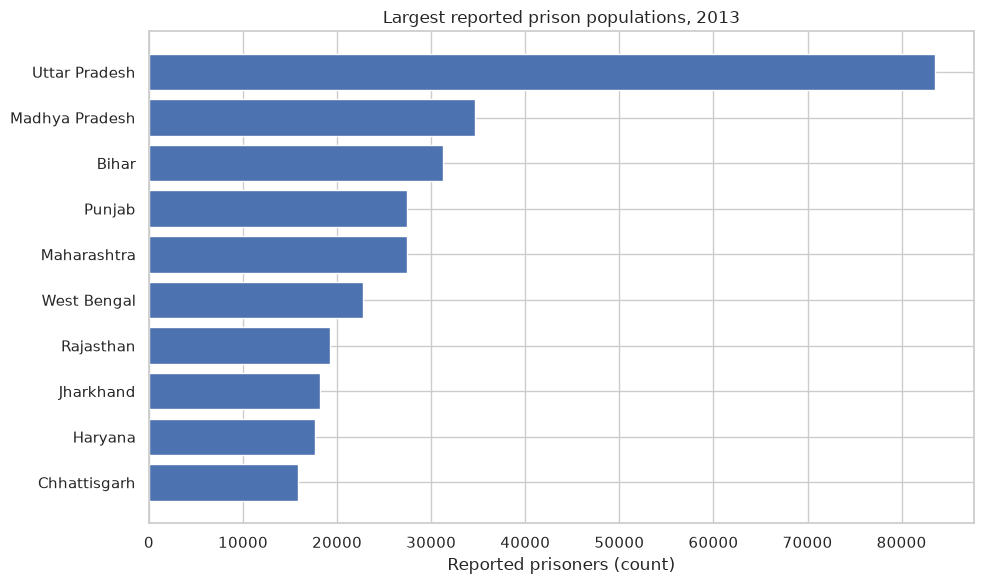

In [2]:
plt.figure(figsize=(10, 6))
top = latest.nlargest(10, 'total_prisoners').sort_values('total_prisoners')
plt.barh(top.state, top.total_prisoners)
plt.xlabel('Reported prisoners (count)')
plt.title('Largest reported prison populations, 2013')
save('01_bar', 'Bar', 'latest_state_snapshot.csv', 'Compare jurisdiction counts.', f'Uttar Pradesh reports {int(top.total_prisoners.max()):,} prisoners, the largest count.')

**Interpretation:** Uttar Pradesh reports 83,518 prisoners, the largest count.

## Jurisdictions with the highest occupancy

Precisely compare a manageable number of numeric values.

Source: `latest_state_snapshot.csv`.

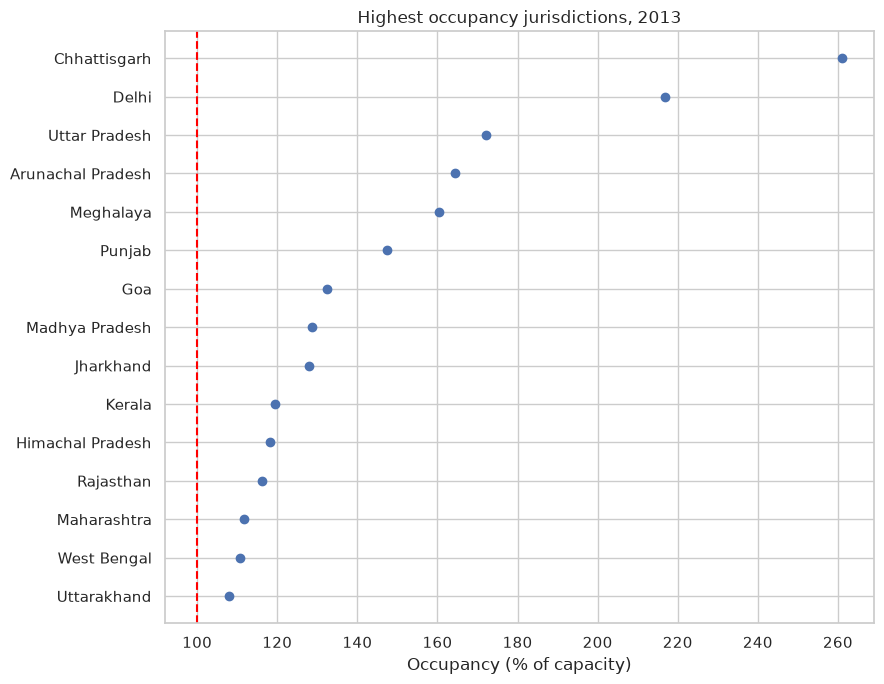

In [3]:
plt.figure(figsize=(9, 7))
d = latest.nlargest(15, 'occupancy_ratio').sort_values('occupancy_ratio')
plt.plot(d.occupancy_ratio * 100, d.state, 'o')
plt.axvline(100, color='red', linestyle='--')
plt.xlabel('Occupancy (% of capacity)')
plt.title('Highest occupancy jurisdictions, 2013')
save('09_dot', 'Dot plot', 'latest_state_snapshot.csv', 'Precisely compare a manageable number of numeric values.', 'Chhattisgarh has the highest reported occupancy at 260.96%; Delhi follows at 216.83%.')

**Interpretation:** Chhattisgarh has the highest reported occupancy at 260.96%; Delhi follows at 216.83%.

## Population growth and capacity

Display temporal changes with fixed geographic coverage.

Source: `year_summary_balanced.csv`.

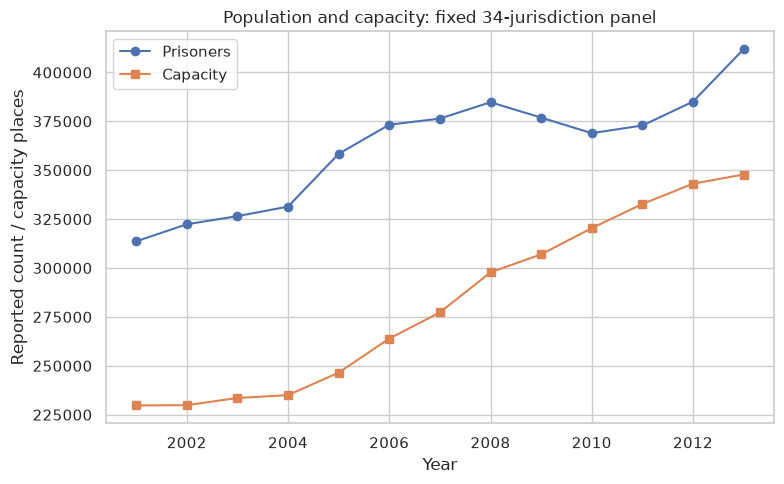

In [4]:
plt.figure(figsize=(8, 5))
plt.plot(year.year, year.prisoners, marker='o', label='Prisoners')
plt.plot(year.year, year.capacity, marker='s', label='Capacity')
plt.legend()
plt.xlabel('Year')
plt.ylabel('Reported count / capacity places')
plt.title('Population and capacity: fixed 34-jurisdiction panel')
save('05_line', 'Line', 'year_summary_balanced.csv', 'Display temporal changes with fixed geographic coverage.', 'Prisoner counts grew 31.33%, compared with 51.41% capacity growth over 2001–2013.')

**Interpretation:** Prisoner counts grew 31.33%, compared with 51.41% capacity growth over 2001–2013.

## Legal-status composition

Mutually exclusive statuses form one population.

Source: `demographic_year.csv`.

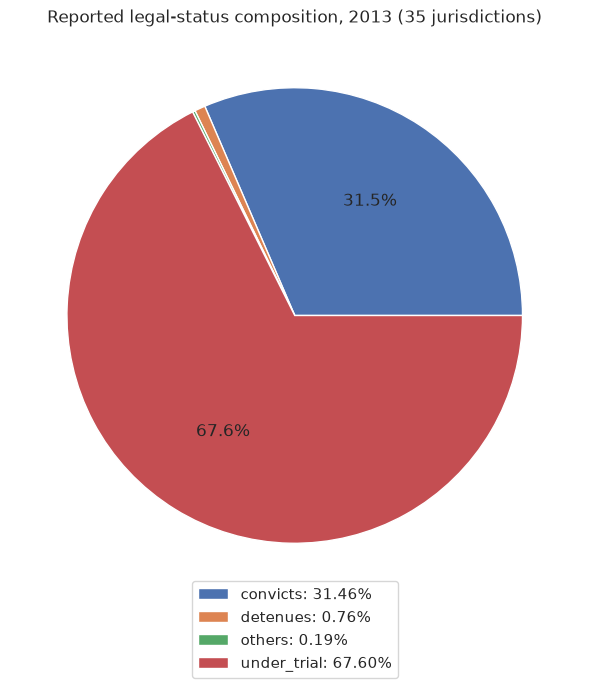

In [5]:
plt.figure(figsize=(7, 7))
status = demo[(demo.year == 2013) & (demo.dimension == 'legal_status')]
wedges, *_ = plt.pie(status.prisoners, autopct=lambda pct: f'{pct:.1f}%' if pct >= 2 else '')
plt.legend(wedges, [f'{name}: {100 * count / status.prisoners.sum():.2f}%' for name, count in zip(status.category, status.prisoners)], loc='lower center', bbox_to_anchor=(0.5, -0.15))
plt.title('Reported legal-status composition, 2013 (35 jurisdictions)')
save('02_pie', 'Pie', 'demographic_year.csv', 'Mutually exclusive statuses form one population.', 'Undertrials account for 67.60% of the 411,992 reported prisoners.')

**Interpretation:** Undertrials account for 67.60% of the 411,992 reported prisoners.

## How legal-status populations change

Show disjoint category contributions through time.

Source: `year_summary_balanced.csv`.

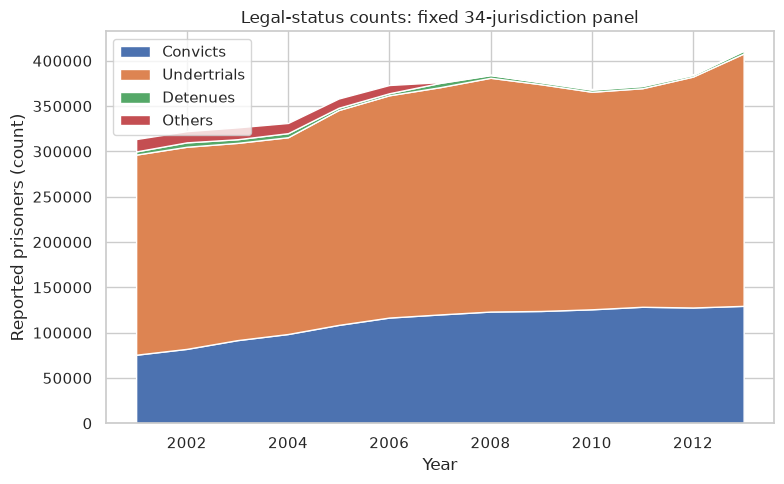

In [6]:
plt.figure(figsize=(8, 5))
plt.stackplot(year.year, year.convicts, year.undertrials, year.detenues, year.others, labels=['Convicts', 'Undertrials', 'Detenues', 'Others'])
plt.legend(loc='upper left')
plt.xlabel('Year')
plt.ylabel('Reported prisoners (count)')
plt.title('Legal-status counts: fixed 34-jurisdiction panel')
save('08_area', 'Stacked area', 'year_summary_balanced.csv', 'Show disjoint category contributions through time.', 'Undertrials remain the largest category throughout the fixed-panel series.')

**Interpretation:** Undertrials remain the largest category throughout the fixed-panel series.

## Convicted and undertrial population rankings

Separate status rankings reveal differences hidden by total population.

Source: `latest_state_snapshot.csv`.

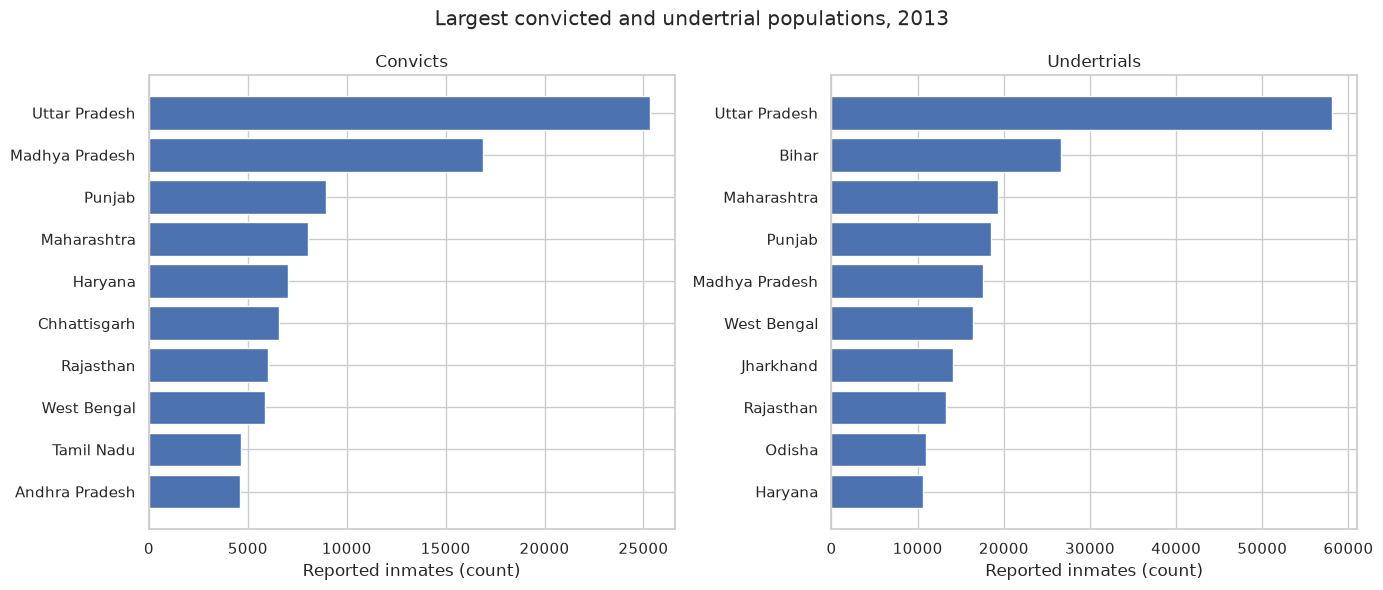

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, field, title in zip(axes, ['convicts', 'under_trial'], ['Convicts', 'Undertrials']):
    d = latest.nlargest(10, field).sort_values(field)
    ax.barh(d.state, d[field])
    ax.set_title(title)
    ax.set_xlabel('Reported inmates (count)')
fig.suptitle(f'Largest convicted and undertrial populations, {latest_year}')
finish('11_status_state_rankings', 'Paired bars', latest[['state', 'year', 'convicts', 'under_trial']], f"Largest convict population: {latest.loc[latest.convicts.idxmax(), 'state']}; largest undertrial population: {latest.loc[latest.under_trial.idxmax(), 'state']}.", 'Separate status rankings reveal differences hidden by total population.', 'latest_state_snapshot.csv')

**Interpretation:** Largest convict population: Uttar Pradesh; largest undertrial population: Uttar Pradesh.

## Gender and caste within legal statuses

Compare observed compositions within convicted and undertrial populations.

Source: `latest_state_snapshot.csv; demographic_status_year.csv`.

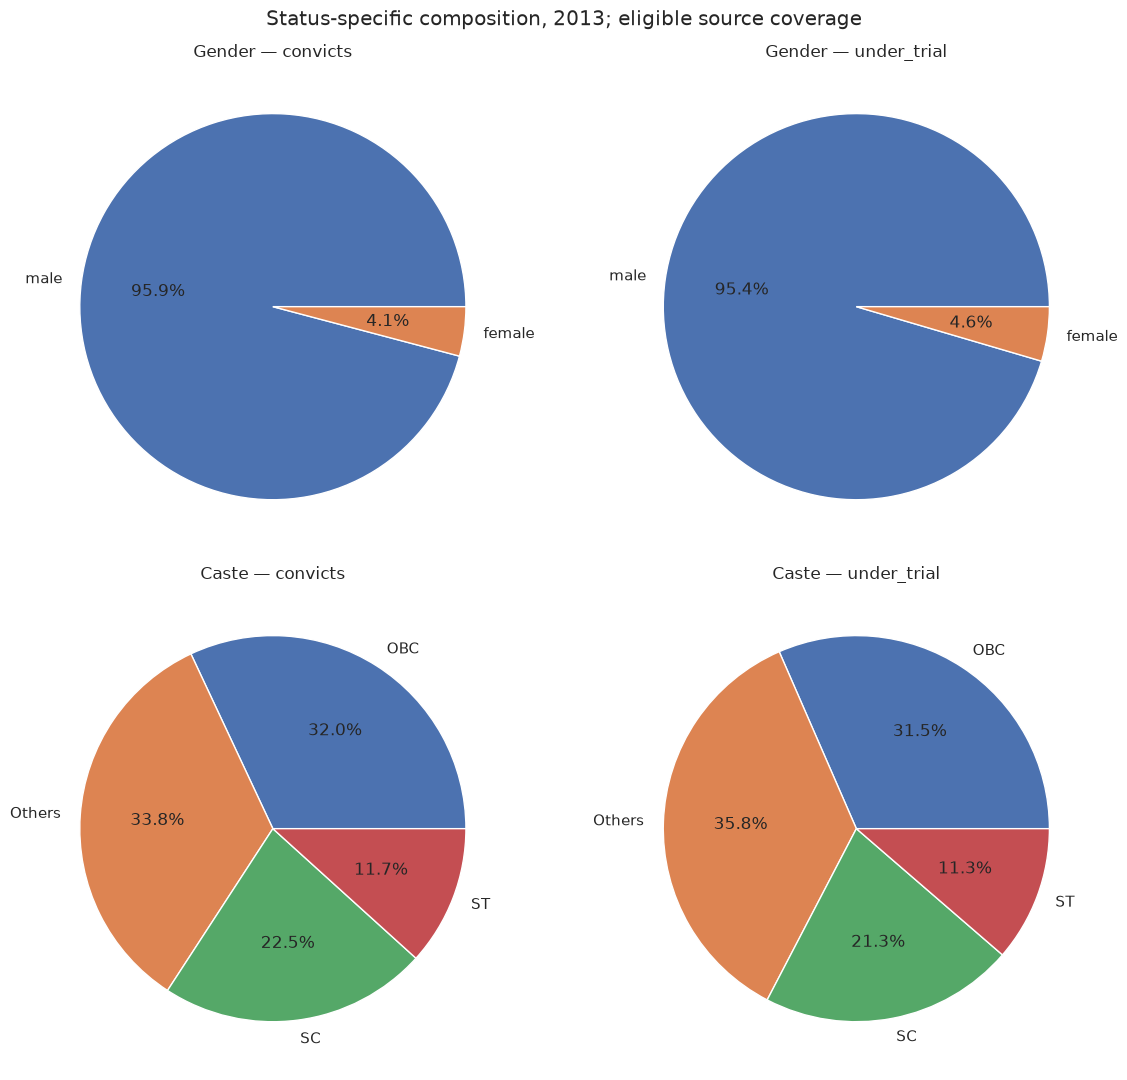

In [8]:
caste = statuses[(statuses.source == 'Caste.csv') & (statuses.year == latest_year) & statuses.legal_status.isin(['convicts', 'under_trial'])]
gender = []
for status in ['convicts', 'under_trial']:
    for sex in ['male', 'female']:
        gender.append(dict(legal_status=status, category=sex, prisoners=int(latest[sex + '_' + status].sum())))
gender = pd.DataFrame(gender)
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
for j, status in enumerate(['convicts', 'under_trial']):
    for i, data in enumerate([gender, caste]):
        d = data[data.legal_status == status]
        axes[i, j].pie(d.prisoners, autopct='%1.1f%%', labels=d.category)
        axes[i, j].set_title(('Gender' if i == 0 else 'Caste') + ' — ' + status)
fig.suptitle(f'Status-specific composition, {latest_year}; eligible source coverage')
combined = pd.concat([gender.assign(dimension='gender'), caste.assign(dimension='caste')], ignore_index=True)
finish('12_status_demographics', 'Composition panels', combined, f"Female shares are {100 * gender[(gender.legal_status == 'convicts') & (gender.category == 'female')].prisoners.sum() / gender[gender.legal_status == 'convicts'].prisoners.sum():.2f}% among convicts and {100 * gender[(gender.legal_status == 'under_trial') & (gender.category == 'female')].prisoners.sum() / gender[gender.legal_status == 'under_trial'].prisoners.sum():.2f}% among undertrials. Caste and gender are overlapping margins.", 'Compare observed compositions within convicted and undertrial populations.', 'latest_state_snapshot.csv; demographic_status_year.csv')

**Interpretation:** Female shares are 4.12% among convicts and 4.56% among undertrials. Caste and gender are overlapping margins.

## Religion and education profiles

Labeled bars make small categories easier to compare than crowded pie slices.

Source: `demographic_status_year.csv`.

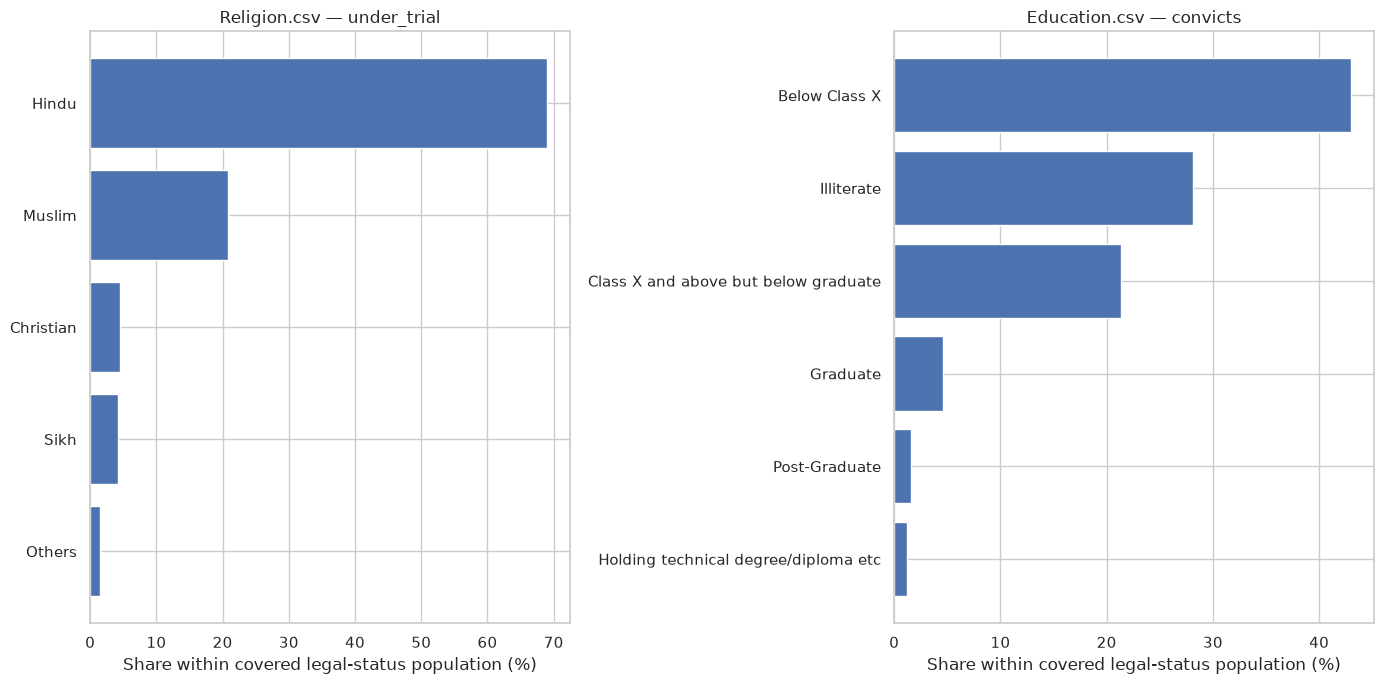

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
pieces = []
for ax, source, status in zip(axes, ['Religion.csv', 'Education.csv'], ['under_trial', 'convicts']):
    d = statuses[(statuses.source == source) & (statuses.year == latest_year) & (statuses.legal_status == status)].sort_values('prisoners')
    ax.barh(d.category, d.share_within_status * 100)
    ax.set_xlabel('Share within covered legal-status population (%)')
    ax.set_title(source + ' — ' + status)
    pieces.append(d)
finish('16_religion_education', 'Demographic share bars', pd.concat(pieces), 'Religion uses the explicitly repaired religion column; these two panels describe different legal-status populations.', 'Labeled bars make small categories easier to compare than crowded pie slices.', 'demographic_status_year.csv')

**Interpretation:** Religion uses the explicitly repaired religion column; these two panels describe different legal-status populations.

## Composition of convicted IPC inmates

Compare all 21 heads without an unreadable 21-slice pie.

Source: `IPC_crime_inmates_convicted.csv, eligible cleaned view`.

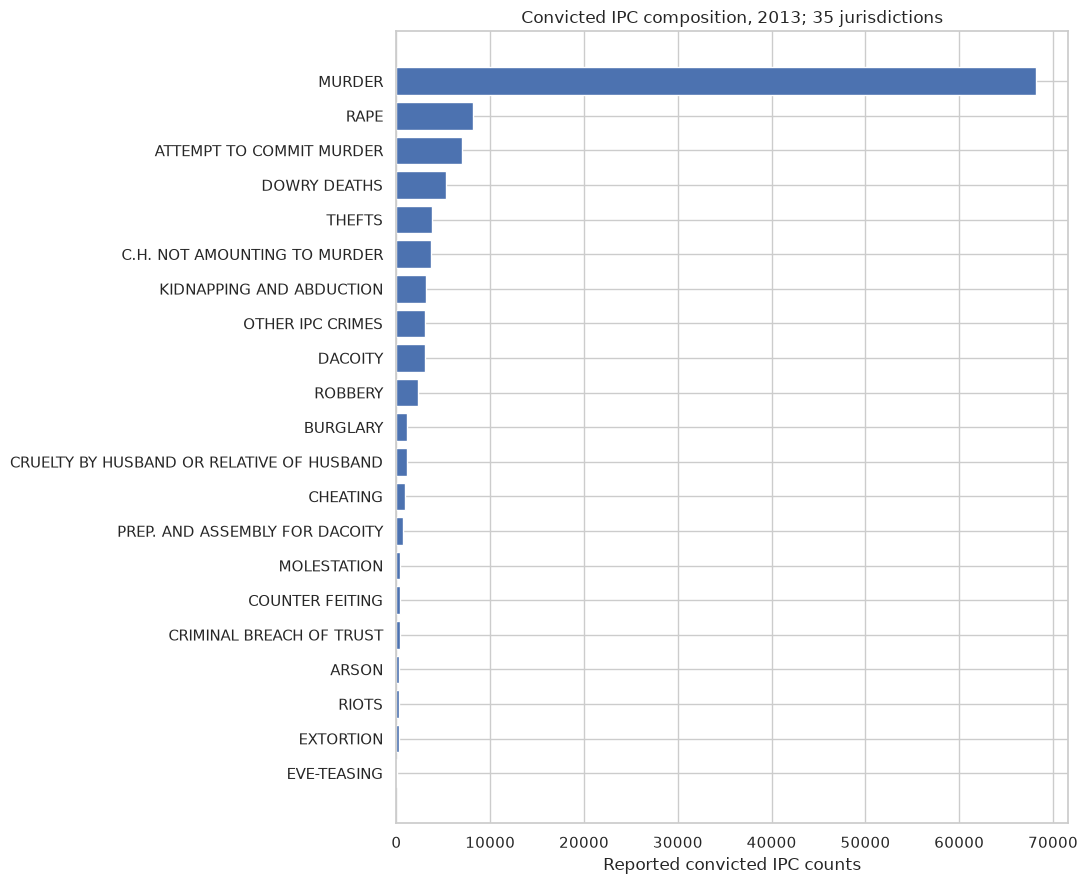

In [10]:
crime = load_descriptive_view(root, 'IPC_crime_inmates_convicted.csv')
measures = [c for c in crime if c.startswith(('Male ', 'Female '))]
crime = crime.assign(reported_count=crime[measures].sum(axis=1))
current = crime[crime.year == latest_year]
totals = current.groupby('CRIME HEAD').reported_count.sum().sort_values()
plt.figure(figsize=(11, 9))
plt.barh(totals.index, totals.values)
plt.xlabel('Reported convicted IPC counts')
plt.title(f'Convicted IPC composition, {latest_year}; {current.state.nunique()} jurisdictions')
finish('17_ipc_composition', 'Crime composition bars', totals.rename('reported_count').reset_index(), f"Murder represents {100 * totals['MURDER'] / totals.sum():.2f}% of this source's reported convicted IPC counts, not all prisoners or resident crime incidence.", 'Compare all 21 heads without an unreadable 21-slice pie.', 'IPC_crime_inmates_convicted.csv, eligible cleaned view')

**Interpretation:** Murder represents 59.99% of this source's reported convicted IPC counts, not all prisoners or resident crime incidence.

## Women-related crime-head trends

Separate axes retain interpretable scales for different source crime heads.

Source: `IPC_crime_inmates_convicted.csv, eligible fixed-coverage view`.

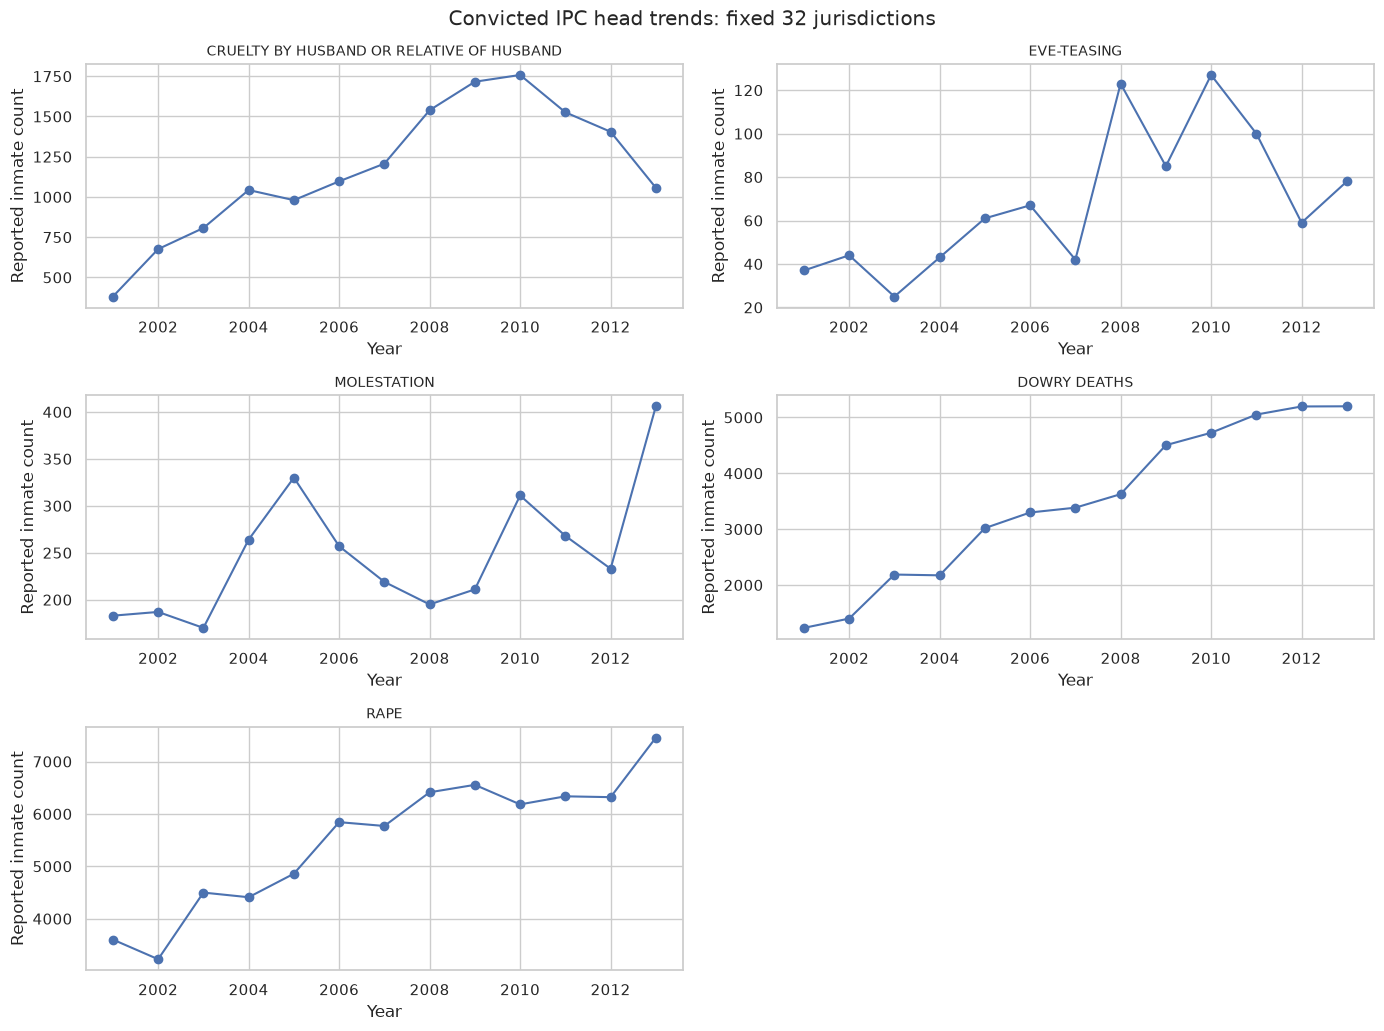

In [11]:
complete = crime.groupby('state').year.nunique()
fixed = crime[crime.state.isin(complete[complete == 13].index)]
groups = {'women_related': ['CRUELTY BY HUSBAND OR RELATIVE OF HUSBAND', 'EVE-TEASING', 'MOLESTATION', 'DOWRY DEATHS', 'RAPE'], 'property': ['BURGLARY', 'DACOITY', 'PREP. AND ASSEMBLY FOR DACOITY', 'ROBBERY', 'THEFTS'], 'fraud': ['CHEATING', 'COUNTER FEITING', 'CRIMINAL BREACH OF TRUST'], 'other_selected': ['ARSON', 'ATTEMPT TO COMMIT MURDER', 'C.H. NOT AMOUNTING TO MURDER', 'KIDNAPPING AND ABDUCTION', 'OTHER IPC CRIMES', 'RIOTS'], 'murder': ['MURDER']}
index = 18
name = 'women_related'
heads = ['CRUELTY BY HUSBAND OR RELATIVE OF HUSBAND', 'EVE-TEASING', 'MOLESTATION', 'DOWRY DEATHS', 'RAPE']
rows = math.ceil(len(heads) / 2)
fig, axes = plt.subplots(rows, 2, figsize=(14, 3.5 * rows), squeeze=False)
trend = fixed[fixed['CRIME HEAD'].isin(heads)].groupby(['year', 'CRIME HEAD']).reported_count.sum().reset_index()
for ax, head in zip(axes.flat, heads):
    d = trend[trend['CRIME HEAD'] == head]
    ax.plot(d.year, d.reported_count, marker='o')
    ax.set_title(head, fontsize=10)
    ax.set_xlabel('Year')
    ax.set_ylabel('Reported inmate count')
for ax in list(axes.flat)[len(heads):]:
    ax.set_visible(False)
fig.suptitle(f'Convicted IPC head trends: fixed {fixed.state.nunique()} jurisdictions')
finish(f'{index:02d}_crime_trends_{name}', 'Crime trend facets', trend, f"For {heads[0]}, reported counts change from {int(trend[(trend.year == trend.year.min()) & (trend['CRIME HEAD'] == heads[0])].reported_count.sum()):,} to {int(trend[(trend.year == trend.year.max()) & (trend['CRIME HEAD'] == heads[0])].reported_count.sum()):,} over 2001–2013 on {fixed.state.nunique()} fixed jurisdictions. These are convicted-inmate counts, not crime incidence.", 'Separate axes retain interpretable scales for different source crime heads.', 'IPC_crime_inmates_convicted.csv, eligible fixed-coverage view')

**Interpretation:** For CRUELTY BY HUSBAND OR RELATIVE OF HUSBAND, reported counts change from 381 to 1,057 over 2001–2013 on 32 fixed jurisdictions. These are convicted-inmate counts, not crime incidence.

## Property crime-head trends

Separate axes retain interpretable scales for different source crime heads.

Source: `IPC_crime_inmates_convicted.csv, eligible fixed-coverage view`.

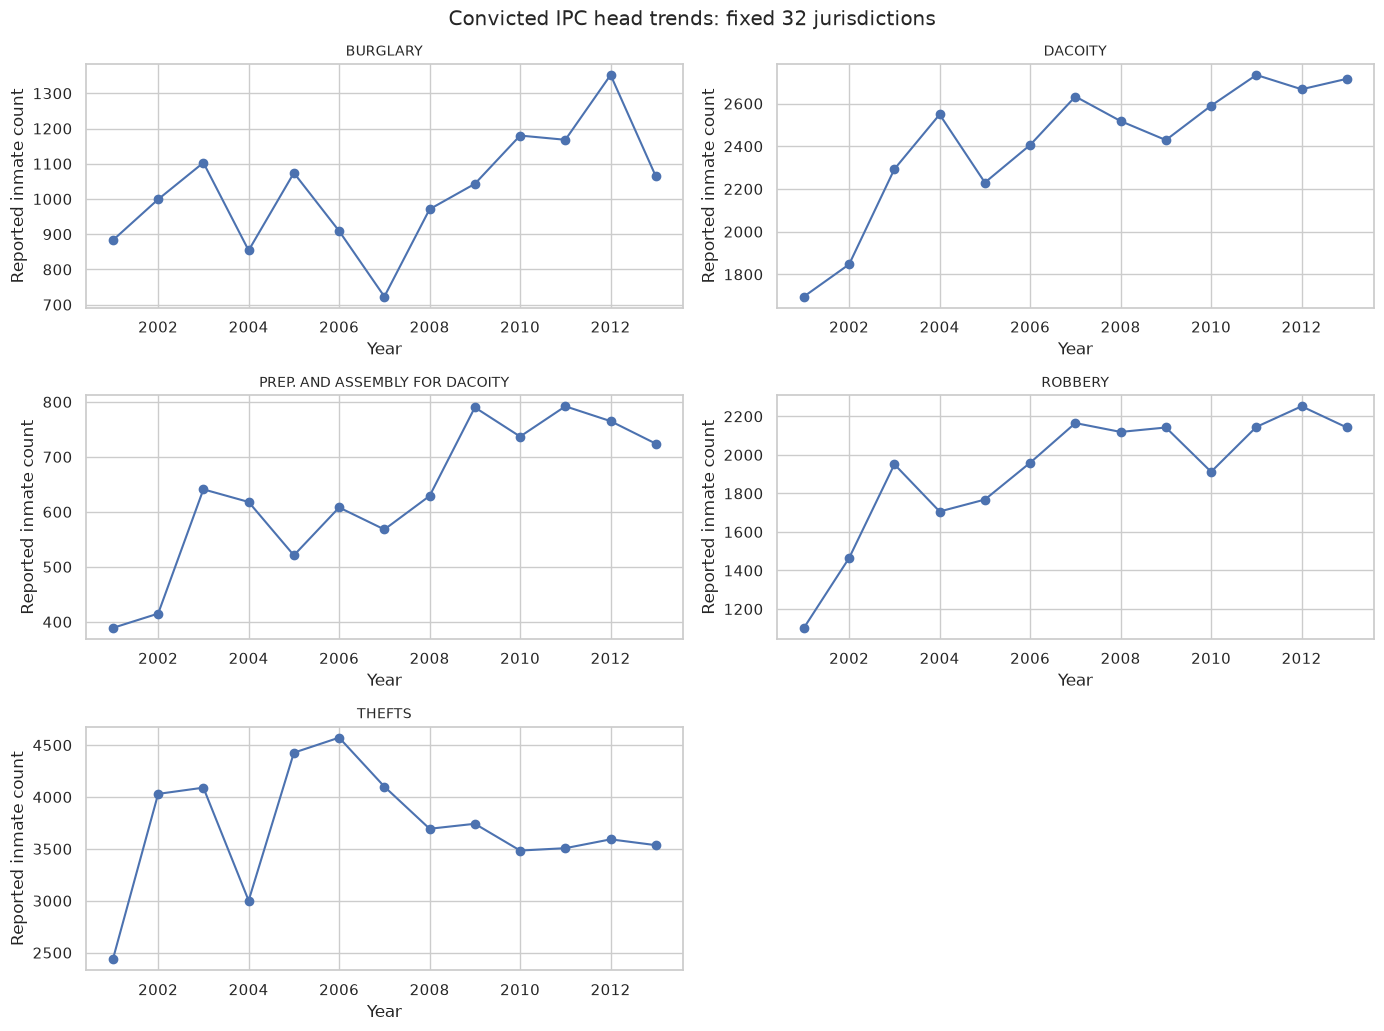

In [12]:
complete = crime.groupby('state').year.nunique()
fixed = crime[crime.state.isin(complete[complete == 13].index)]
groups = {'women_related': ['CRUELTY BY HUSBAND OR RELATIVE OF HUSBAND', 'EVE-TEASING', 'MOLESTATION', 'DOWRY DEATHS', 'RAPE'], 'property': ['BURGLARY', 'DACOITY', 'PREP. AND ASSEMBLY FOR DACOITY', 'ROBBERY', 'THEFTS'], 'fraud': ['CHEATING', 'COUNTER FEITING', 'CRIMINAL BREACH OF TRUST'], 'other_selected': ['ARSON', 'ATTEMPT TO COMMIT MURDER', 'C.H. NOT AMOUNTING TO MURDER', 'KIDNAPPING AND ABDUCTION', 'OTHER IPC CRIMES', 'RIOTS'], 'murder': ['MURDER']}
index = 19
name = 'property'
heads = ['BURGLARY', 'DACOITY', 'PREP. AND ASSEMBLY FOR DACOITY', 'ROBBERY', 'THEFTS']
rows = math.ceil(len(heads) / 2)
fig, axes = plt.subplots(rows, 2, figsize=(14, 3.5 * rows), squeeze=False)
trend = fixed[fixed['CRIME HEAD'].isin(heads)].groupby(['year', 'CRIME HEAD']).reported_count.sum().reset_index()
for ax, head in zip(axes.flat, heads):
    d = trend[trend['CRIME HEAD'] == head]
    ax.plot(d.year, d.reported_count, marker='o')
    ax.set_title(head, fontsize=10)
    ax.set_xlabel('Year')
    ax.set_ylabel('Reported inmate count')
for ax in list(axes.flat)[len(heads):]:
    ax.set_visible(False)
fig.suptitle(f'Convicted IPC head trends: fixed {fixed.state.nunique()} jurisdictions')
finish(f'{index:02d}_crime_trends_{name}', 'Crime trend facets', trend, f"For {heads[0]}, reported counts change from {int(trend[(trend.year == trend.year.min()) & (trend['CRIME HEAD'] == heads[0])].reported_count.sum()):,} to {int(trend[(trend.year == trend.year.max()) & (trend['CRIME HEAD'] == heads[0])].reported_count.sum()):,} over 2001–2013 on {fixed.state.nunique()} fixed jurisdictions. These are convicted-inmate counts, not crime incidence.", 'Separate axes retain interpretable scales for different source crime heads.', 'IPC_crime_inmates_convicted.csv, eligible fixed-coverage view')

**Interpretation:** For BURGLARY, reported counts change from 883 to 1,064 over 2001–2013 on 32 fixed jurisdictions. These are convicted-inmate counts, not crime incidence.

## Fraud crime-head trends

Separate axes retain interpretable scales for different source crime heads.

Source: `IPC_crime_inmates_convicted.csv, eligible fixed-coverage view`.

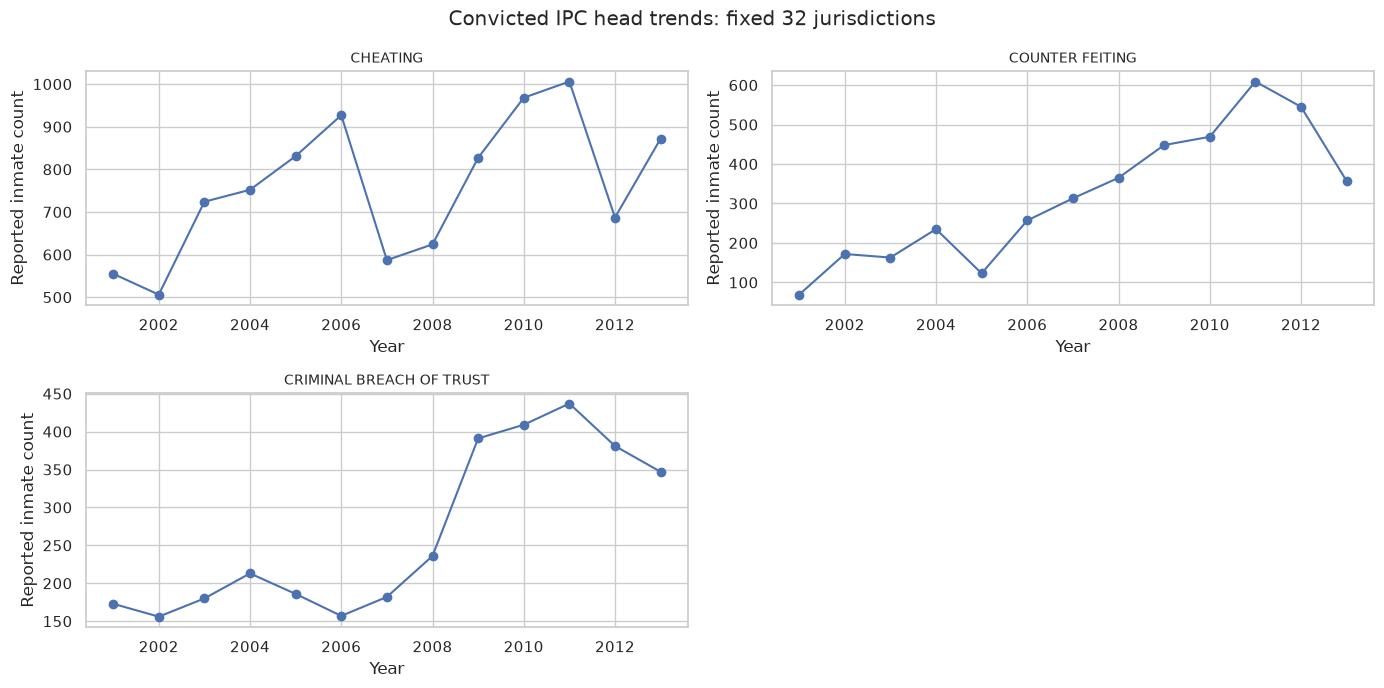

In [13]:
complete = crime.groupby('state').year.nunique()
fixed = crime[crime.state.isin(complete[complete == 13].index)]
groups = {'women_related': ['CRUELTY BY HUSBAND OR RELATIVE OF HUSBAND', 'EVE-TEASING', 'MOLESTATION', 'DOWRY DEATHS', 'RAPE'], 'property': ['BURGLARY', 'DACOITY', 'PREP. AND ASSEMBLY FOR DACOITY', 'ROBBERY', 'THEFTS'], 'fraud': ['CHEATING', 'COUNTER FEITING', 'CRIMINAL BREACH OF TRUST'], 'other_selected': ['ARSON', 'ATTEMPT TO COMMIT MURDER', 'C.H. NOT AMOUNTING TO MURDER', 'KIDNAPPING AND ABDUCTION', 'OTHER IPC CRIMES', 'RIOTS'], 'murder': ['MURDER']}
index = 20
name = 'fraud'
heads = ['CHEATING', 'COUNTER FEITING', 'CRIMINAL BREACH OF TRUST']
rows = math.ceil(len(heads) / 2)
fig, axes = plt.subplots(rows, 2, figsize=(14, 3.5 * rows), squeeze=False)
trend = fixed[fixed['CRIME HEAD'].isin(heads)].groupby(['year', 'CRIME HEAD']).reported_count.sum().reset_index()
for ax, head in zip(axes.flat, heads):
    d = trend[trend['CRIME HEAD'] == head]
    ax.plot(d.year, d.reported_count, marker='o')
    ax.set_title(head, fontsize=10)
    ax.set_xlabel('Year')
    ax.set_ylabel('Reported inmate count')
for ax in list(axes.flat)[len(heads):]:
    ax.set_visible(False)
fig.suptitle(f'Convicted IPC head trends: fixed {fixed.state.nunique()} jurisdictions')
finish(f'{index:02d}_crime_trends_{name}', 'Crime trend facets', trend, f"For {heads[0]}, reported counts change from {int(trend[(trend.year == trend.year.min()) & (trend['CRIME HEAD'] == heads[0])].reported_count.sum()):,} to {int(trend[(trend.year == trend.year.max()) & (trend['CRIME HEAD'] == heads[0])].reported_count.sum()):,} over 2001–2013 on {fixed.state.nunique()} fixed jurisdictions. These are convicted-inmate counts, not crime incidence.", 'Separate axes retain interpretable scales for different source crime heads.', 'IPC_crime_inmates_convicted.csv, eligible fixed-coverage view')

**Interpretation:** For CHEATING, reported counts change from 555 to 872 over 2001–2013 on 32 fixed jurisdictions. These are convicted-inmate counts, not crime incidence.

## Other selected crime-head trends

Separate axes retain interpretable scales for different source crime heads.

Source: `IPC_crime_inmates_convicted.csv, eligible fixed-coverage view`.

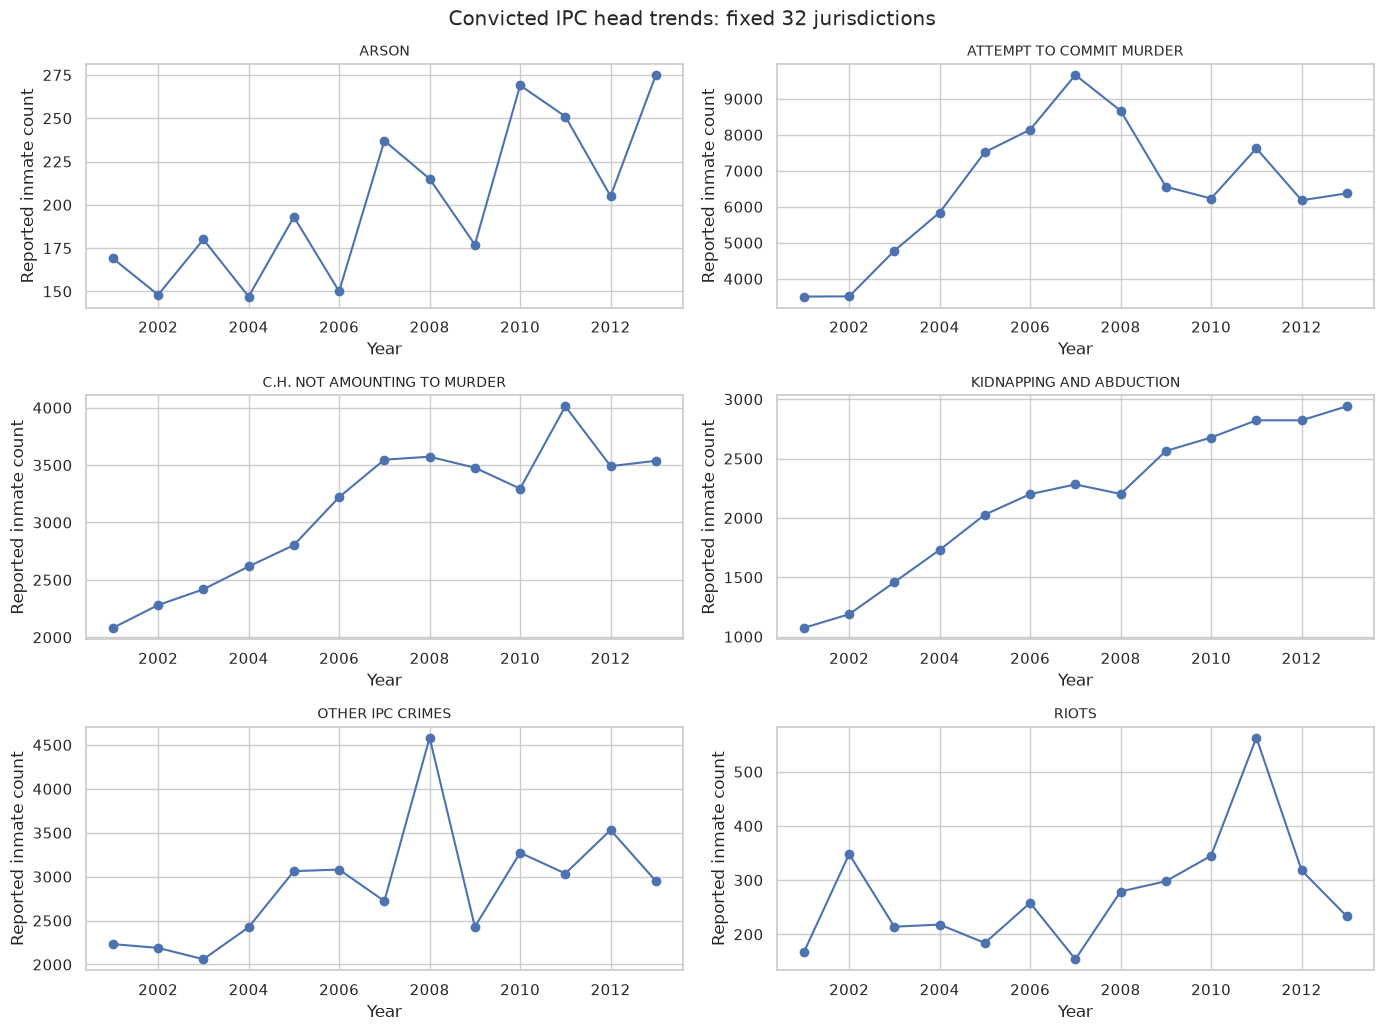

In [14]:
complete = crime.groupby('state').year.nunique()
fixed = crime[crime.state.isin(complete[complete == 13].index)]
groups = {'women_related': ['CRUELTY BY HUSBAND OR RELATIVE OF HUSBAND', 'EVE-TEASING', 'MOLESTATION', 'DOWRY DEATHS', 'RAPE'], 'property': ['BURGLARY', 'DACOITY', 'PREP. AND ASSEMBLY FOR DACOITY', 'ROBBERY', 'THEFTS'], 'fraud': ['CHEATING', 'COUNTER FEITING', 'CRIMINAL BREACH OF TRUST'], 'other_selected': ['ARSON', 'ATTEMPT TO COMMIT MURDER', 'C.H. NOT AMOUNTING TO MURDER', 'KIDNAPPING AND ABDUCTION', 'OTHER IPC CRIMES', 'RIOTS'], 'murder': ['MURDER']}
index = 21
name = 'other_selected'
heads = ['ARSON', 'ATTEMPT TO COMMIT MURDER', 'C.H. NOT AMOUNTING TO MURDER', 'KIDNAPPING AND ABDUCTION', 'OTHER IPC CRIMES', 'RIOTS']
rows = math.ceil(len(heads) / 2)
fig, axes = plt.subplots(rows, 2, figsize=(14, 3.5 * rows), squeeze=False)
trend = fixed[fixed['CRIME HEAD'].isin(heads)].groupby(['year', 'CRIME HEAD']).reported_count.sum().reset_index()
for ax, head in zip(axes.flat, heads):
    d = trend[trend['CRIME HEAD'] == head]
    ax.plot(d.year, d.reported_count, marker='o')
    ax.set_title(head, fontsize=10)
    ax.set_xlabel('Year')
    ax.set_ylabel('Reported inmate count')
for ax in list(axes.flat)[len(heads):]:
    ax.set_visible(False)
fig.suptitle(f'Convicted IPC head trends: fixed {fixed.state.nunique()} jurisdictions')
finish(f'{index:02d}_crime_trends_{name}', 'Crime trend facets', trend, f"For {heads[0]}, reported counts change from {int(trend[(trend.year == trend.year.min()) & (trend['CRIME HEAD'] == heads[0])].reported_count.sum()):,} to {int(trend[(trend.year == trend.year.max()) & (trend['CRIME HEAD'] == heads[0])].reported_count.sum()):,} over 2001–2013 on {fixed.state.nunique()} fixed jurisdictions. These are convicted-inmate counts, not crime incidence.", 'Separate axes retain interpretable scales for different source crime heads.', 'IPC_crime_inmates_convicted.csv, eligible fixed-coverage view')

**Interpretation:** For ARSON, reported counts change from 169 to 275 over 2001–2013 on 32 fixed jurisdictions. These are convicted-inmate counts, not crime incidence.

## Murder-head trend

Separate axes retain interpretable scales for different source crime heads.

Source: `IPC_crime_inmates_convicted.csv, eligible fixed-coverage view`.

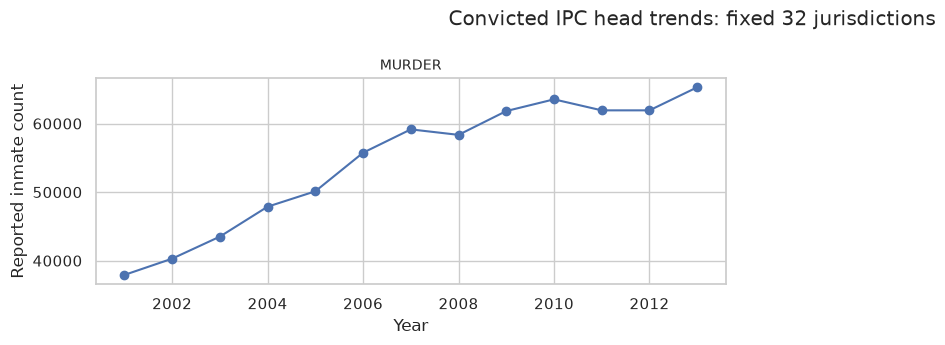

In [15]:
complete = crime.groupby('state').year.nunique()
fixed = crime[crime.state.isin(complete[complete == 13].index)]
groups = {'women_related': ['CRUELTY BY HUSBAND OR RELATIVE OF HUSBAND', 'EVE-TEASING', 'MOLESTATION', 'DOWRY DEATHS', 'RAPE'], 'property': ['BURGLARY', 'DACOITY', 'PREP. AND ASSEMBLY FOR DACOITY', 'ROBBERY', 'THEFTS'], 'fraud': ['CHEATING', 'COUNTER FEITING', 'CRIMINAL BREACH OF TRUST'], 'other_selected': ['ARSON', 'ATTEMPT TO COMMIT MURDER', 'C.H. NOT AMOUNTING TO MURDER', 'KIDNAPPING AND ABDUCTION', 'OTHER IPC CRIMES', 'RIOTS'], 'murder': ['MURDER']}
index = 22
name = 'murder'
heads = ['MURDER']
rows = math.ceil(len(heads) / 2)
fig, axes = plt.subplots(rows, 2, figsize=(14, 3.5 * rows), squeeze=False)
trend = fixed[fixed['CRIME HEAD'].isin(heads)].groupby(['year', 'CRIME HEAD']).reported_count.sum().reset_index()
for ax, head in zip(axes.flat, heads):
    d = trend[trend['CRIME HEAD'] == head]
    ax.plot(d.year, d.reported_count, marker='o')
    ax.set_title(head, fontsize=10)
    ax.set_xlabel('Year')
    ax.set_ylabel('Reported inmate count')
for ax in list(axes.flat)[len(heads):]:
    ax.set_visible(False)
fig.suptitle(f'Convicted IPC head trends: fixed {fixed.state.nunique()} jurisdictions')
finish(f'{index:02d}_crime_trends_{name}', 'Crime trend facets', trend, f"For {heads[0]}, reported counts change from {int(trend[(trend.year == trend.year.min()) & (trend['CRIME HEAD'] == heads[0])].reported_count.sum()):,} to {int(trend[(trend.year == trend.year.max()) & (trend['CRIME HEAD'] == heads[0])].reported_count.sum()):,} over 2001–2013 on {fixed.state.nunique()} fixed jurisdictions. These are convicted-inmate counts, not crime incidence.", 'Separate axes retain interpretable scales for different source crime heads.', 'IPC_crime_inmates_convicted.csv, eligible fixed-coverage view')

**Interpretation:** For MURDER, reported counts change from 37,925 to 65,291 over 2001–2013 on 32 fixed jurisdictions. These are convicted-inmate counts, not crime incidence.

## Women-related crime-head rankings

Compare jurisdictions within each crime head without pooling repeated annual inmate stocks.

Source: `IPC_crime_inmates_convicted.csv, eligible latest-year view`.

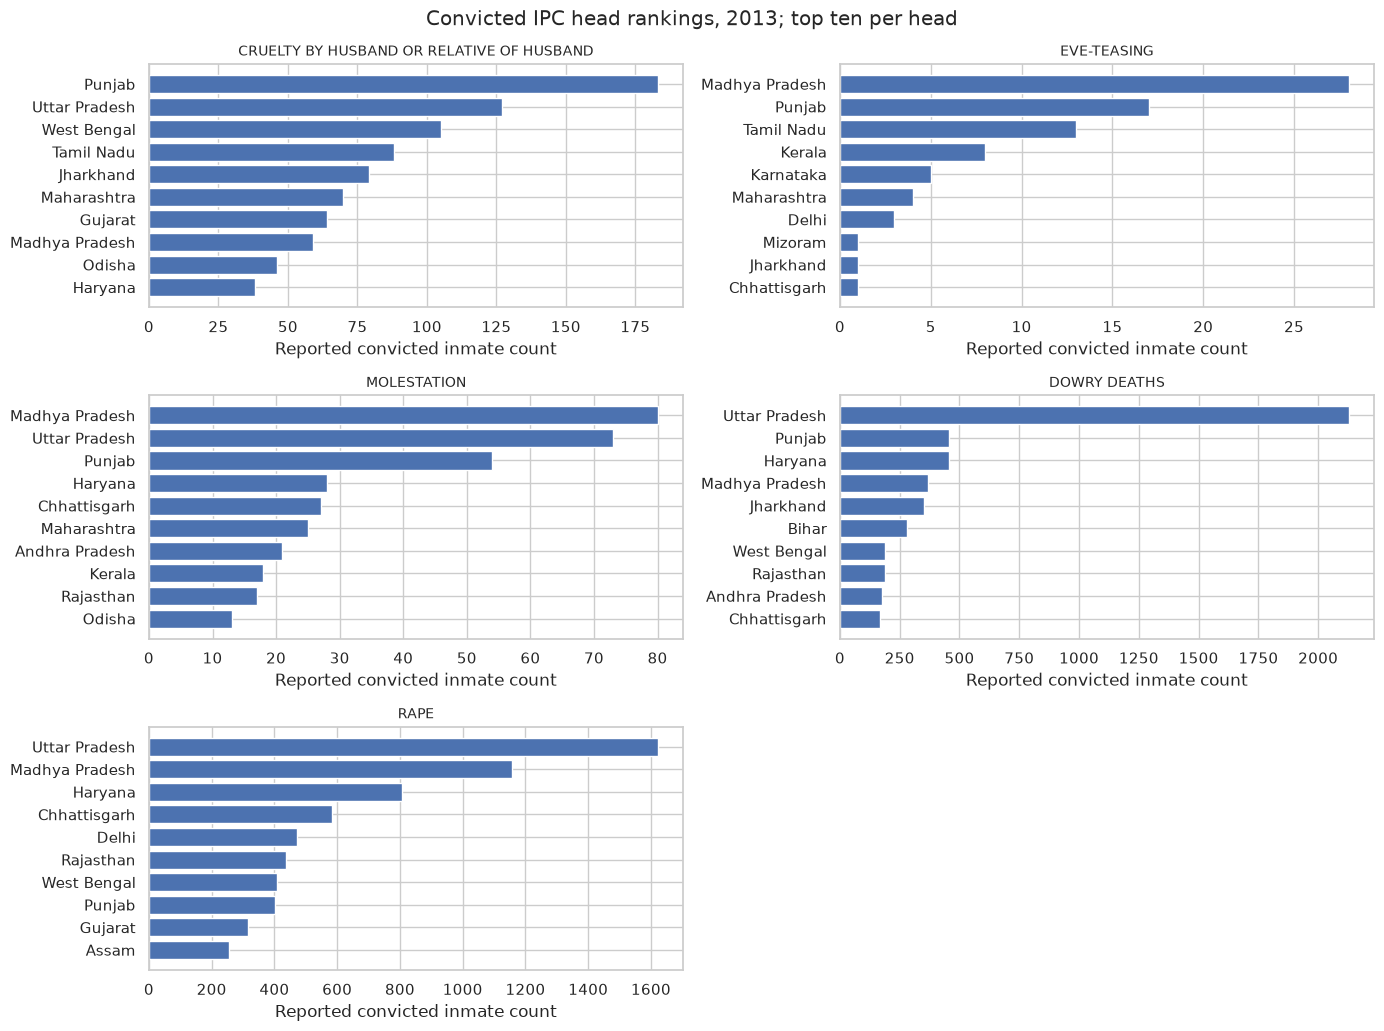

In [16]:
complete = crime.groupby('state').year.nunique()
fixed = crime[crime.state.isin(complete[complete == 13].index)]
groups = {'women_related': ['CRUELTY BY HUSBAND OR RELATIVE OF HUSBAND', 'EVE-TEASING', 'MOLESTATION', 'DOWRY DEATHS', 'RAPE'], 'property': ['BURGLARY', 'DACOITY', 'PREP. AND ASSEMBLY FOR DACOITY', 'ROBBERY', 'THEFTS'], 'fraud': ['CHEATING', 'COUNTER FEITING', 'CRIMINAL BREACH OF TRUST'], 'other_selected': ['ARSON', 'ATTEMPT TO COMMIT MURDER', 'C.H. NOT AMOUNTING TO MURDER', 'KIDNAPPING AND ABDUCTION', 'OTHER IPC CRIMES', 'RIOTS'], 'murder': ['MURDER']}
index = 18
name = 'women_related'
heads = ['CRUELTY BY HUSBAND OR RELATIVE OF HUSBAND', 'EVE-TEASING', 'MOLESTATION', 'DOWRY DEATHS', 'RAPE']
rows = math.ceil(len(heads) / 2)
fig, axes = plt.subplots(rows, 2, figsize=(14, 3.5 * rows), squeeze=False)
ranking = current[current['CRIME HEAD'].isin(heads)][['state', 'year', 'CRIME HEAD', 'reported_count']]
for ax, head in zip(axes.flat, heads):
    d = ranking[ranking['CRIME HEAD'] == head].nlargest(10, 'reported_count').sort_values('reported_count')
    ax.barh(d.state, d.reported_count)
    ax.set_title(head, fontsize=10)
    ax.set_xlabel('Reported convicted inmate count')
for ax in list(axes.flat)[len(heads):]:
    ax.set_visible(False)
fig.suptitle(f'Convicted IPC head rankings, {latest_year}; top ten per head')
finish(f'{index + 5:02d}_crime_rankings_{name}', 'Crime ranking facets', ranking, f"For {heads[0]}, {ranking[ranking['CRIME HEAD'] == heads[0]].nlargest(1, 'reported_count').state.iloc[0]} has the largest reported count ({int(ranking[ranking['CRIME HEAD'] == heads[0]].reported_count.max()):,}) in {latest_year}. This is not a per-resident crime rate.", 'Compare jurisdictions within each crime head without pooling repeated annual inmate stocks.', 'IPC_crime_inmates_convicted.csv, eligible latest-year view')

**Interpretation:** For CRUELTY BY HUSBAND OR RELATIVE OF HUSBAND, Punjab has the largest reported count (183) in 2013. This is not a per-resident crime rate.

## Property crime-head rankings

Compare jurisdictions within each crime head without pooling repeated annual inmate stocks.

Source: `IPC_crime_inmates_convicted.csv, eligible latest-year view`.

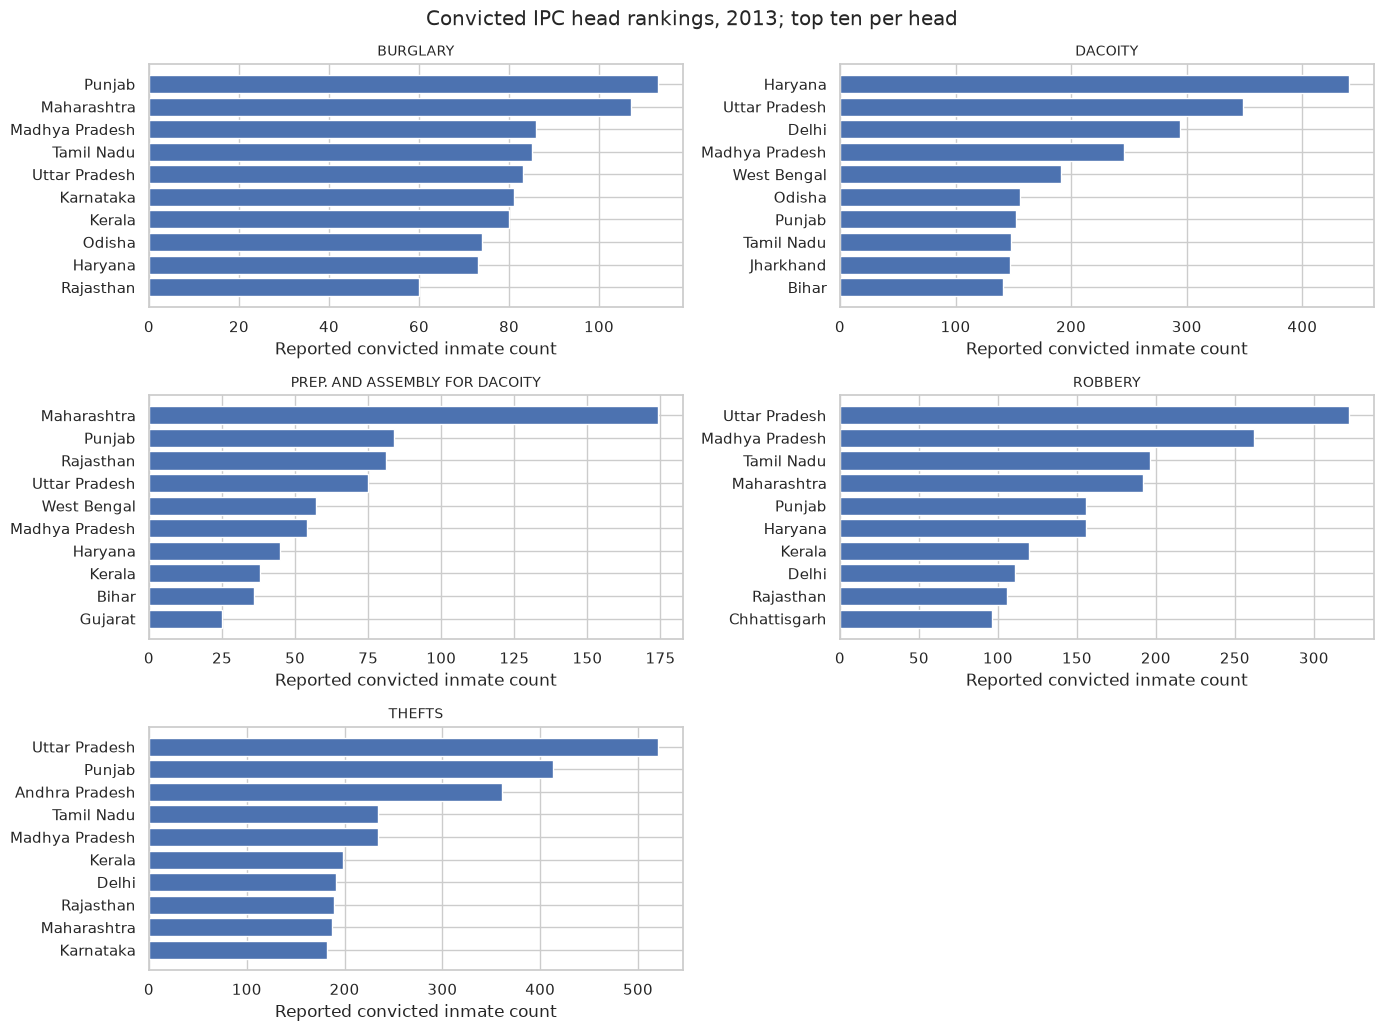

In [17]:
complete = crime.groupby('state').year.nunique()
fixed = crime[crime.state.isin(complete[complete == 13].index)]
groups = {'women_related': ['CRUELTY BY HUSBAND OR RELATIVE OF HUSBAND', 'EVE-TEASING', 'MOLESTATION', 'DOWRY DEATHS', 'RAPE'], 'property': ['BURGLARY', 'DACOITY', 'PREP. AND ASSEMBLY FOR DACOITY', 'ROBBERY', 'THEFTS'], 'fraud': ['CHEATING', 'COUNTER FEITING', 'CRIMINAL BREACH OF TRUST'], 'other_selected': ['ARSON', 'ATTEMPT TO COMMIT MURDER', 'C.H. NOT AMOUNTING TO MURDER', 'KIDNAPPING AND ABDUCTION', 'OTHER IPC CRIMES', 'RIOTS'], 'murder': ['MURDER']}
index = 19
name = 'property'
heads = ['BURGLARY', 'DACOITY', 'PREP. AND ASSEMBLY FOR DACOITY', 'ROBBERY', 'THEFTS']
rows = math.ceil(len(heads) / 2)
fig, axes = plt.subplots(rows, 2, figsize=(14, 3.5 * rows), squeeze=False)
ranking = current[current['CRIME HEAD'].isin(heads)][['state', 'year', 'CRIME HEAD', 'reported_count']]
for ax, head in zip(axes.flat, heads):
    d = ranking[ranking['CRIME HEAD'] == head].nlargest(10, 'reported_count').sort_values('reported_count')
    ax.barh(d.state, d.reported_count)
    ax.set_title(head, fontsize=10)
    ax.set_xlabel('Reported convicted inmate count')
for ax in list(axes.flat)[len(heads):]:
    ax.set_visible(False)
fig.suptitle(f'Convicted IPC head rankings, {latest_year}; top ten per head')
finish(f'{index + 5:02d}_crime_rankings_{name}', 'Crime ranking facets', ranking, f"For {heads[0]}, {ranking[ranking['CRIME HEAD'] == heads[0]].nlargest(1, 'reported_count').state.iloc[0]} has the largest reported count ({int(ranking[ranking['CRIME HEAD'] == heads[0]].reported_count.max()):,}) in {latest_year}. This is not a per-resident crime rate.", 'Compare jurisdictions within each crime head without pooling repeated annual inmate stocks.', 'IPC_crime_inmates_convicted.csv, eligible latest-year view')

**Interpretation:** For BURGLARY, Punjab has the largest reported count (113) in 2013. This is not a per-resident crime rate.

## Fraud crime-head rankings

Compare jurisdictions within each crime head without pooling repeated annual inmate stocks.

Source: `IPC_crime_inmates_convicted.csv, eligible latest-year view`.

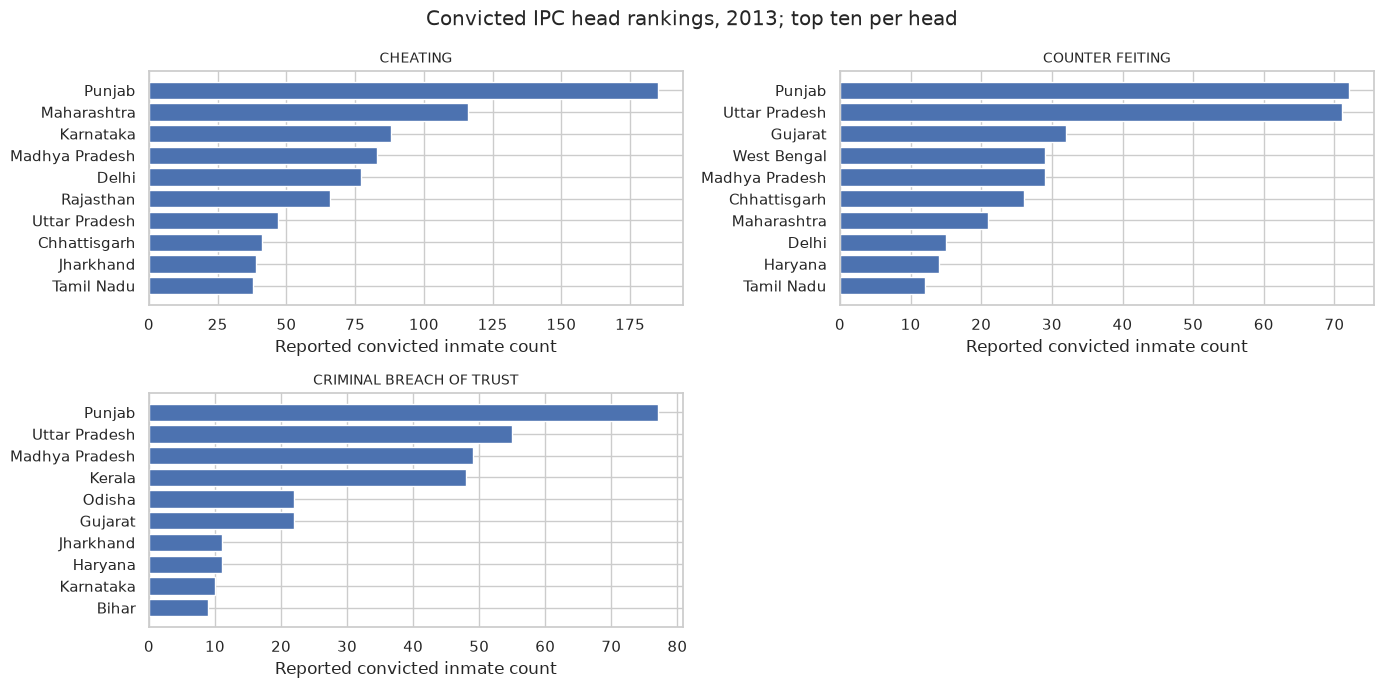

In [18]:
complete = crime.groupby('state').year.nunique()
fixed = crime[crime.state.isin(complete[complete == 13].index)]
groups = {'women_related': ['CRUELTY BY HUSBAND OR RELATIVE OF HUSBAND', 'EVE-TEASING', 'MOLESTATION', 'DOWRY DEATHS', 'RAPE'], 'property': ['BURGLARY', 'DACOITY', 'PREP. AND ASSEMBLY FOR DACOITY', 'ROBBERY', 'THEFTS'], 'fraud': ['CHEATING', 'COUNTER FEITING', 'CRIMINAL BREACH OF TRUST'], 'other_selected': ['ARSON', 'ATTEMPT TO COMMIT MURDER', 'C.H. NOT AMOUNTING TO MURDER', 'KIDNAPPING AND ABDUCTION', 'OTHER IPC CRIMES', 'RIOTS'], 'murder': ['MURDER']}
index = 20
name = 'fraud'
heads = ['CHEATING', 'COUNTER FEITING', 'CRIMINAL BREACH OF TRUST']
rows = math.ceil(len(heads) / 2)
fig, axes = plt.subplots(rows, 2, figsize=(14, 3.5 * rows), squeeze=False)
ranking = current[current['CRIME HEAD'].isin(heads)][['state', 'year', 'CRIME HEAD', 'reported_count']]
for ax, head in zip(axes.flat, heads):
    d = ranking[ranking['CRIME HEAD'] == head].nlargest(10, 'reported_count').sort_values('reported_count')
    ax.barh(d.state, d.reported_count)
    ax.set_title(head, fontsize=10)
    ax.set_xlabel('Reported convicted inmate count')
for ax in list(axes.flat)[len(heads):]:
    ax.set_visible(False)
fig.suptitle(f'Convicted IPC head rankings, {latest_year}; top ten per head')
finish(f'{index + 5:02d}_crime_rankings_{name}', 'Crime ranking facets', ranking, f"For {heads[0]}, {ranking[ranking['CRIME HEAD'] == heads[0]].nlargest(1, 'reported_count').state.iloc[0]} has the largest reported count ({int(ranking[ranking['CRIME HEAD'] == heads[0]].reported_count.max()):,}) in {latest_year}. This is not a per-resident crime rate.", 'Compare jurisdictions within each crime head without pooling repeated annual inmate stocks.', 'IPC_crime_inmates_convicted.csv, eligible latest-year view')

**Interpretation:** For CHEATING, Punjab has the largest reported count (185) in 2013. This is not a per-resident crime rate.

## Other selected crime-head rankings

Compare jurisdictions within each crime head without pooling repeated annual inmate stocks.

Source: `IPC_crime_inmates_convicted.csv, eligible latest-year view`.

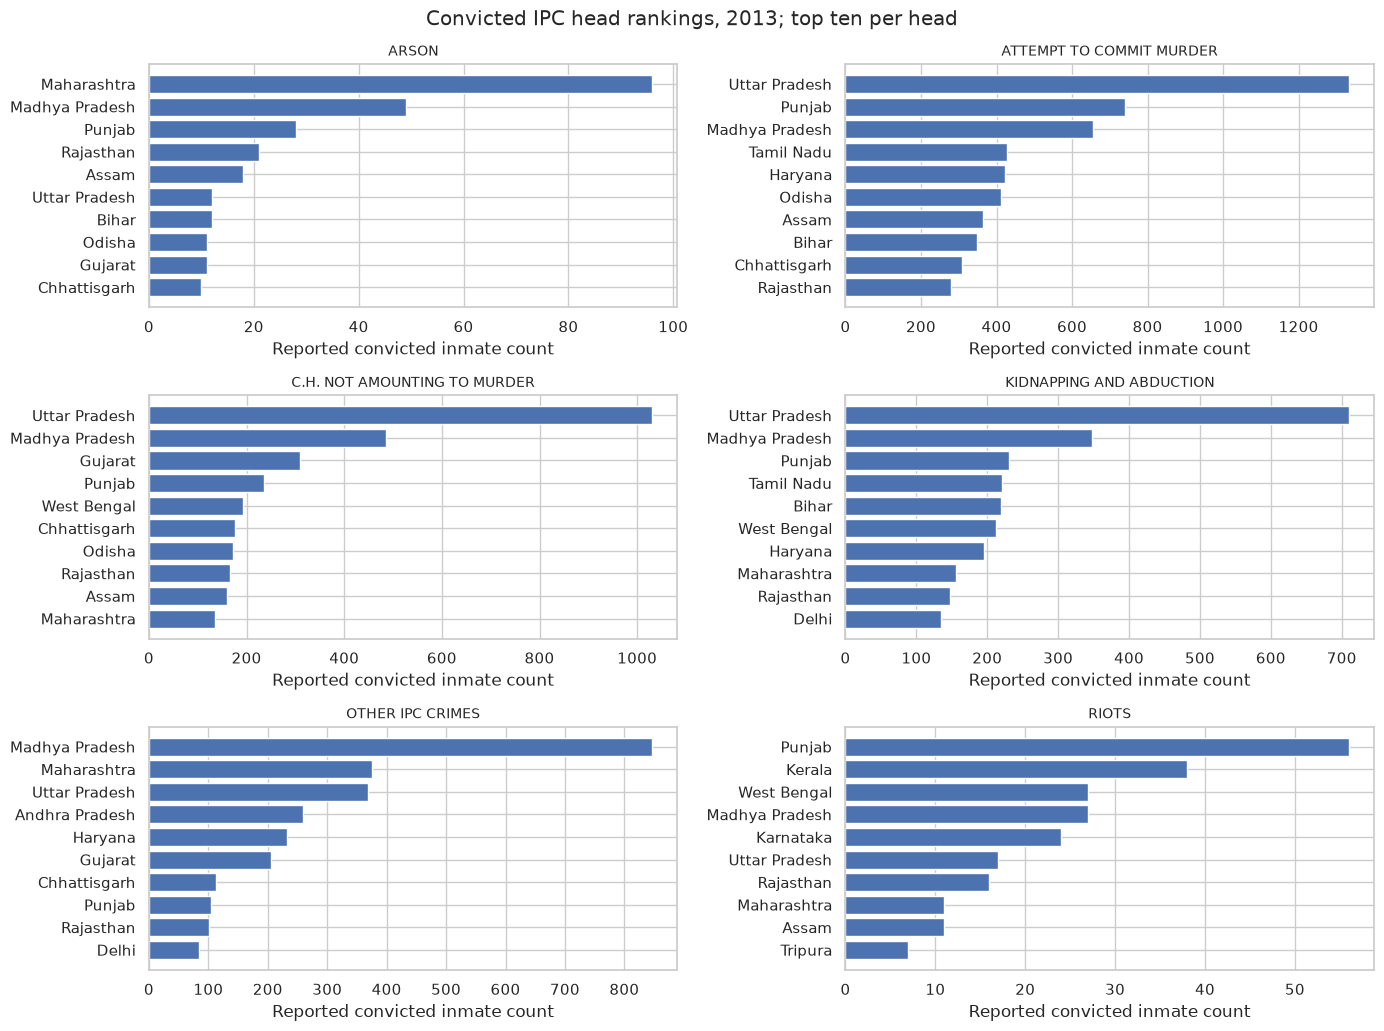

In [19]:
complete = crime.groupby('state').year.nunique()
fixed = crime[crime.state.isin(complete[complete == 13].index)]
groups = {'women_related': ['CRUELTY BY HUSBAND OR RELATIVE OF HUSBAND', 'EVE-TEASING', 'MOLESTATION', 'DOWRY DEATHS', 'RAPE'], 'property': ['BURGLARY', 'DACOITY', 'PREP. AND ASSEMBLY FOR DACOITY', 'ROBBERY', 'THEFTS'], 'fraud': ['CHEATING', 'COUNTER FEITING', 'CRIMINAL BREACH OF TRUST'], 'other_selected': ['ARSON', 'ATTEMPT TO COMMIT MURDER', 'C.H. NOT AMOUNTING TO MURDER', 'KIDNAPPING AND ABDUCTION', 'OTHER IPC CRIMES', 'RIOTS'], 'murder': ['MURDER']}
index = 21
name = 'other_selected'
heads = ['ARSON', 'ATTEMPT TO COMMIT MURDER', 'C.H. NOT AMOUNTING TO MURDER', 'KIDNAPPING AND ABDUCTION', 'OTHER IPC CRIMES', 'RIOTS']
rows = math.ceil(len(heads) / 2)
fig, axes = plt.subplots(rows, 2, figsize=(14, 3.5 * rows), squeeze=False)
ranking = current[current['CRIME HEAD'].isin(heads)][['state', 'year', 'CRIME HEAD', 'reported_count']]
for ax, head in zip(axes.flat, heads):
    d = ranking[ranking['CRIME HEAD'] == head].nlargest(10, 'reported_count').sort_values('reported_count')
    ax.barh(d.state, d.reported_count)
    ax.set_title(head, fontsize=10)
    ax.set_xlabel('Reported convicted inmate count')
for ax in list(axes.flat)[len(heads):]:
    ax.set_visible(False)
fig.suptitle(f'Convicted IPC head rankings, {latest_year}; top ten per head')
finish(f'{index + 5:02d}_crime_rankings_{name}', 'Crime ranking facets', ranking, f"For {heads[0]}, {ranking[ranking['CRIME HEAD'] == heads[0]].nlargest(1, 'reported_count').state.iloc[0]} has the largest reported count ({int(ranking[ranking['CRIME HEAD'] == heads[0]].reported_count.max()):,}) in {latest_year}. This is not a per-resident crime rate.", 'Compare jurisdictions within each crime head without pooling repeated annual inmate stocks.', 'IPC_crime_inmates_convicted.csv, eligible latest-year view')

**Interpretation:** For ARSON, Maharashtra has the largest reported count (96) in 2013. This is not a per-resident crime rate.

## Murder-head ranking

Compare jurisdictions within each crime head without pooling repeated annual inmate stocks.

Source: `IPC_crime_inmates_convicted.csv, eligible latest-year view`.

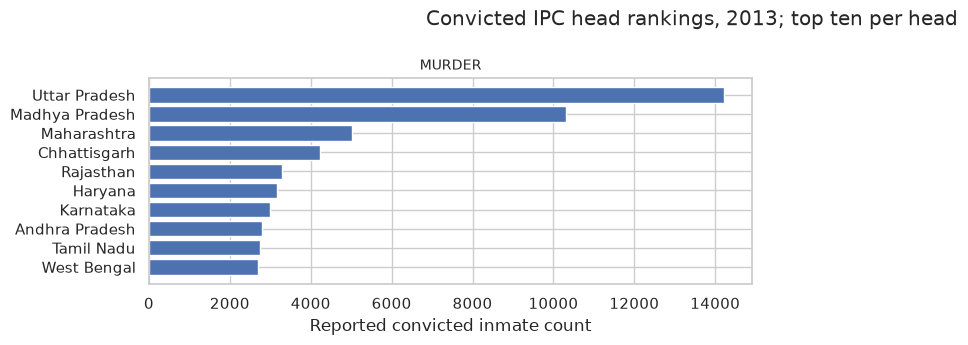

In [20]:
complete = crime.groupby('state').year.nunique()
fixed = crime[crime.state.isin(complete[complete == 13].index)]
groups = {'women_related': ['CRUELTY BY HUSBAND OR RELATIVE OF HUSBAND', 'EVE-TEASING', 'MOLESTATION', 'DOWRY DEATHS', 'RAPE'], 'property': ['BURGLARY', 'DACOITY', 'PREP. AND ASSEMBLY FOR DACOITY', 'ROBBERY', 'THEFTS'], 'fraud': ['CHEATING', 'COUNTER FEITING', 'CRIMINAL BREACH OF TRUST'], 'other_selected': ['ARSON', 'ATTEMPT TO COMMIT MURDER', 'C.H. NOT AMOUNTING TO MURDER', 'KIDNAPPING AND ABDUCTION', 'OTHER IPC CRIMES', 'RIOTS'], 'murder': ['MURDER']}
index = 22
name = 'murder'
heads = ['MURDER']
rows = math.ceil(len(heads) / 2)
fig, axes = plt.subplots(rows, 2, figsize=(14, 3.5 * rows), squeeze=False)
ranking = current[current['CRIME HEAD'].isin(heads)][['state', 'year', 'CRIME HEAD', 'reported_count']]
for ax, head in zip(axes.flat, heads):
    d = ranking[ranking['CRIME HEAD'] == head].nlargest(10, 'reported_count').sort_values('reported_count')
    ax.barh(d.state, d.reported_count)
    ax.set_title(head, fontsize=10)
    ax.set_xlabel('Reported convicted inmate count')
for ax in list(axes.flat)[len(heads):]:
    ax.set_visible(False)
fig.suptitle(f'Convicted IPC head rankings, {latest_year}; top ten per head')
finish(f'{index + 5:02d}_crime_rankings_{name}', 'Crime ranking facets', ranking, f"For {heads[0]}, {ranking[ranking['CRIME HEAD'] == heads[0]].nlargest(1, 'reported_count').state.iloc[0]} has the largest reported count ({int(ranking[ranking['CRIME HEAD'] == heads[0]].reported_count.max()):,}) in {latest_year}. This is not a per-resident crime rate.", 'Compare jurisdictions within each crime head without pooling repeated annual inmate stocks.', 'IPC_crime_inmates_convicted.csv, eligible latest-year view')

**Interpretation:** For MURDER, Uttar Pradesh has the largest reported count (14,211) in 2013. This is not a per-resident crime rate.

## Sentence-source indicator rankings

Compare source-specific indicators without confusing them with the entire sentenced population.

Source: `Death_sentence.csv, eligible cleaned view`.

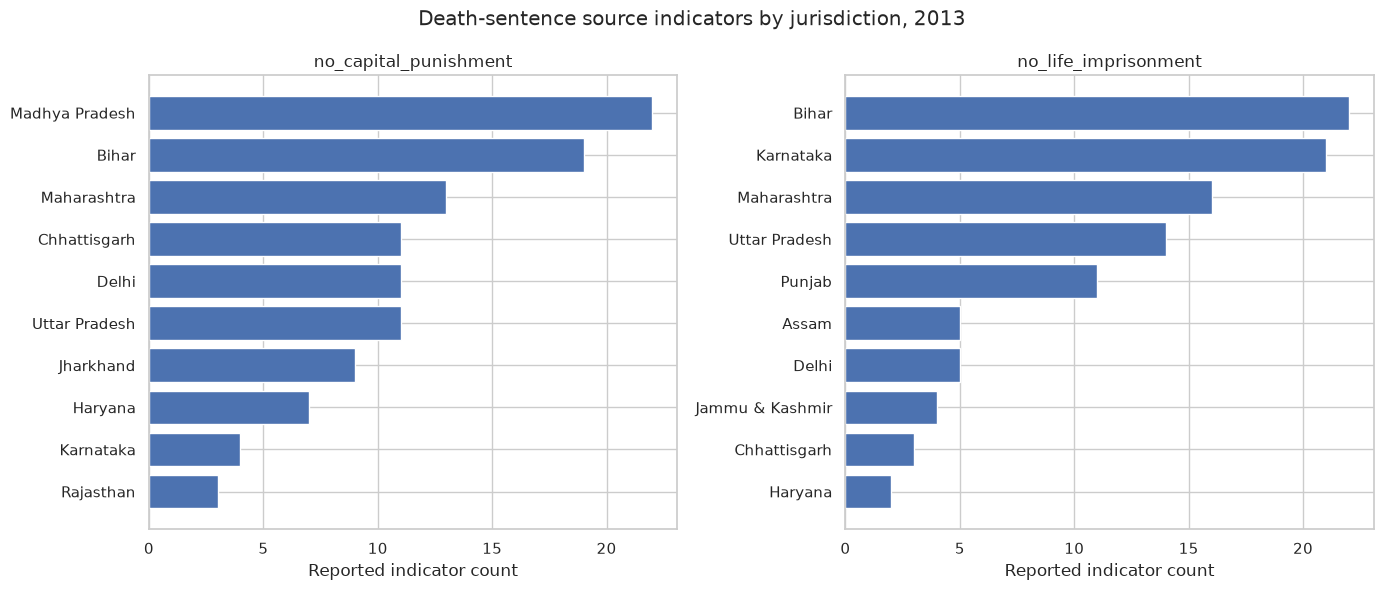

In [21]:
death = load_descriptive_view(root, 'Death_sentence.csv')
fields = ['no_capital_punishment', 'no_life_imprisonment']
current = death[death.year == latest_year]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, field in zip(axes, fields):
    d = current.nlargest(10, field).sort_values(field)
    ax.barh(d.state, d[field])
    ax.set_xlabel('Reported indicator count')
    ax.set_title(field)
fig.suptitle(f'Death-sentence source indicators by jurisdiction, {latest_year}')
finish('14_sentence_indicator_rankings', 'Indicator rank panels', current[['state', 'year'] + fields], 'These source field names are retained literally; no_life_imprisonment is not assumed to describe every life-sentenced inmate.', 'Compare source-specific indicators without confusing them with the entire sentenced population.', 'Death_sentence.csv, eligible cleaned view')

**Interpretation:** These source field names are retained literally; no_life_imprisonment is not assumed to describe every life-sentenced inmate.

## Sentence-source indicator trends

Prevent geographic coverage changes from masquerading as indicator changes.

Source: `Death_sentence.csv, eligible cleaned view`.

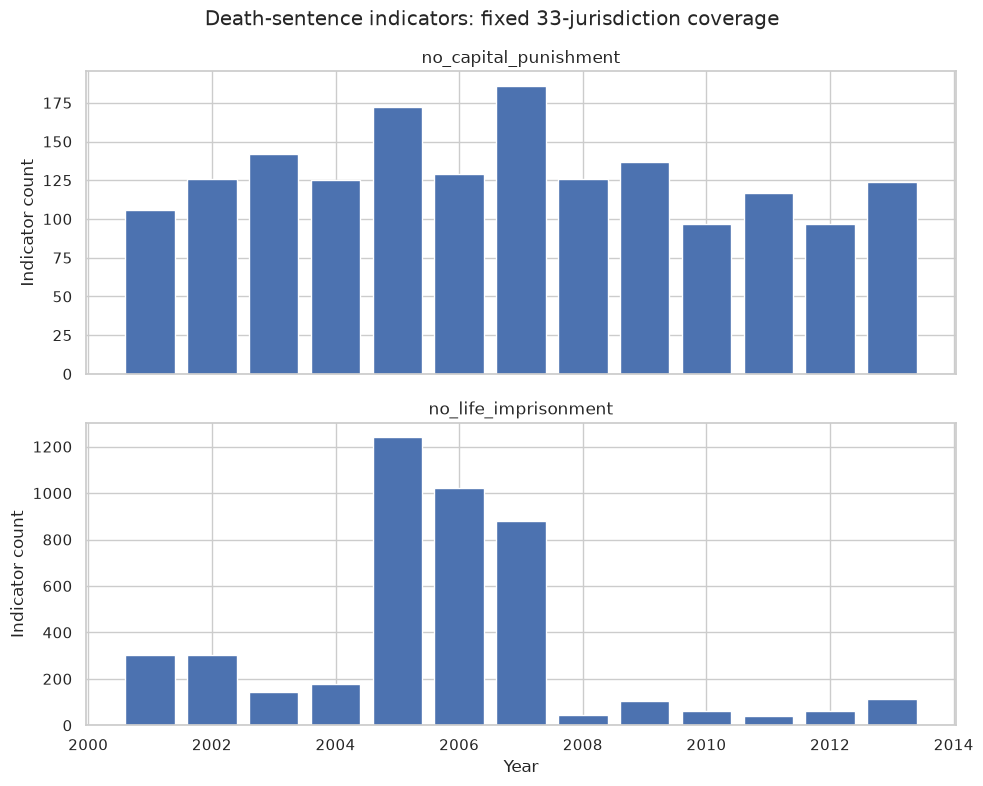

In [22]:
complete = death.groupby('state').year.nunique()
fixed = death[death.state.isin(complete[complete == 13].index)]
annual = fixed.groupby('year')[fields].sum().reset_index()
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
for ax, field in zip(axes, fields):
    ax.bar(annual.year, annual[field])
    ax.set_ylabel('Indicator count')
    ax.set_title(field)
axes[-1].set_xlabel('Year')
fig.suptitle(f'Death-sentence indicators: fixed {fixed.state.nunique()}-jurisdiction coverage')
finish('15_sentence_indicator_trends', 'Annual indicator panels', annual, f'Trends use the same {fixed.state.nunique()} jurisdictions in all thirteen years; the two indicators are not added together.', 'Prevent geographic coverage changes from masquerading as indicator changes.', 'Death_sentence.csv, eligible cleaned view')

**Interpretation:** Trends use the same 33 jurisdictions in all thirteen years; the two indicators are not added together.

## Distribution of occupancy

Show the numeric occupancy distribution.

Source: `profile_features.csv`.

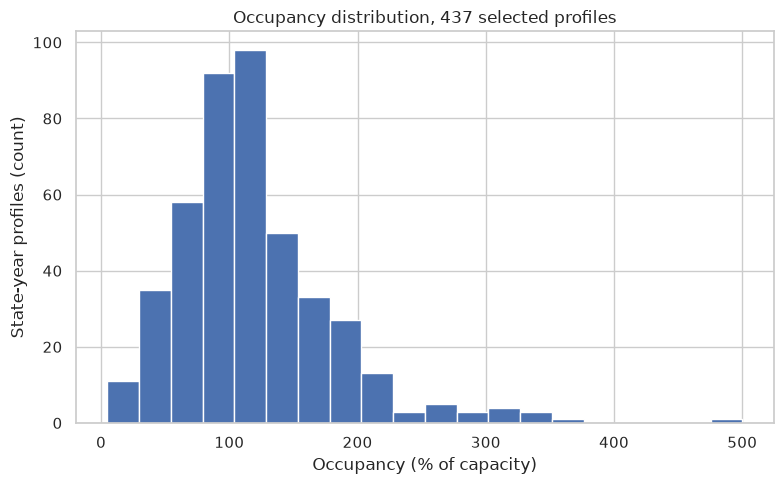

In [23]:
plt.figure(figsize=(8, 5))
plt.hist(profiles.occupancy_ratio * 100, bins=20, edgecolor='white')
plt.xlabel('Occupancy (% of capacity)')
plt.ylabel('State-year profiles (count)')
plt.title('Occupancy distribution, 437 selected profiles')
save('03_histogram', 'Histogram', 'profile_features.csv', 'Show the numeric occupancy distribution.', f'The median occupancy is {profiles.occupancy_ratio.median() * 100:.2f}%; the maximum is {profiles.occupancy_ratio.max() * 100:.0f}%.')

**Interpretation:** The median occupancy is 110.33%; the maximum is 500%.

## Changes in occupancy distributions

Compare medians, dispersion and extreme observations.

Source: `state_year_totals.csv`.

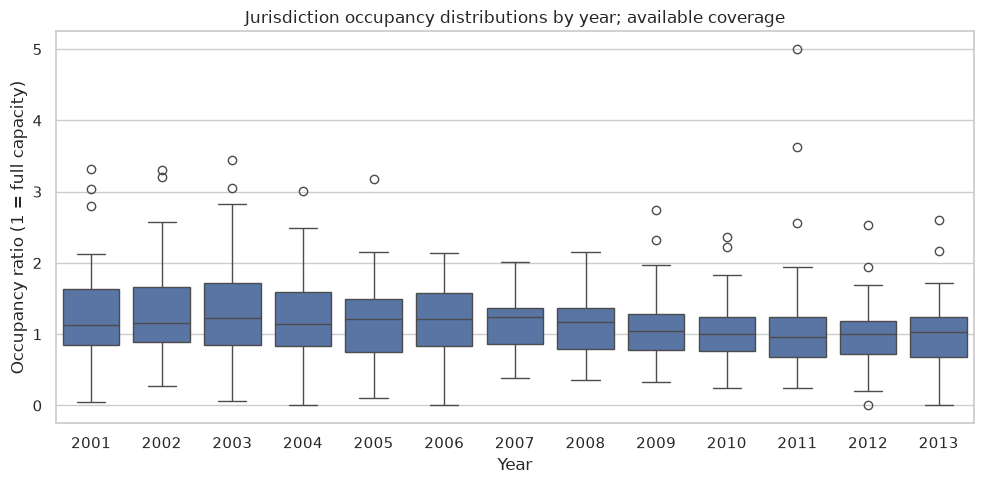

In [24]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=panel, x='year', y='occupancy_ratio')
plt.xlabel('Year')
plt.ylabel('Occupancy ratio (1 = full capacity)')
plt.title('Jurisdiction occupancy distributions by year; available coverage')
save('04_box', 'Box plot', 'state_year_totals.csv', 'Compare medians, dispersion and extreme observations.', 'Coverage changes from 34 to 35 jurisdictions after 2008; outliers are retained.')

**Interpretation:** Coverage changes from 34 to 35 jurisdictions after 2008; outliers are retained.

## Illiteracy and occupancy

Inspect paired numerical values without causal claims.

Source: `profile_features.csv`.

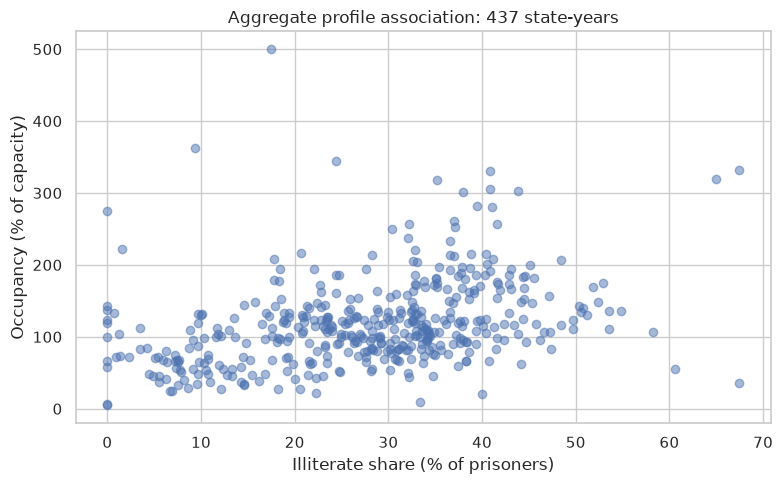

In [25]:
plt.figure(figsize=(8, 5))
plt.scatter(profiles.illiterate_share * 100, profiles.occupancy_ratio * 100, alpha=0.5)
plt.xlabel('Illiterate share (% of prisoners)')
plt.ylabel('Occupancy (% of capacity)')
plt.title('Aggregate profile association: 437 state-years')
save('06_scatter', 'Scatter', 'profile_features.csv', 'Inspect paired numerical values without causal claims.', 'Pooled Pearson correlation is 0.35432; repeated state-years are not independent people.')

**Interpretation:** Pooled Pearson correlation is 0.35432; repeated state-years are not independent people.

## Relationships between profile features

Compare all feature-pair associations on one consistent cohort.

Source: `profile_features.csv`.

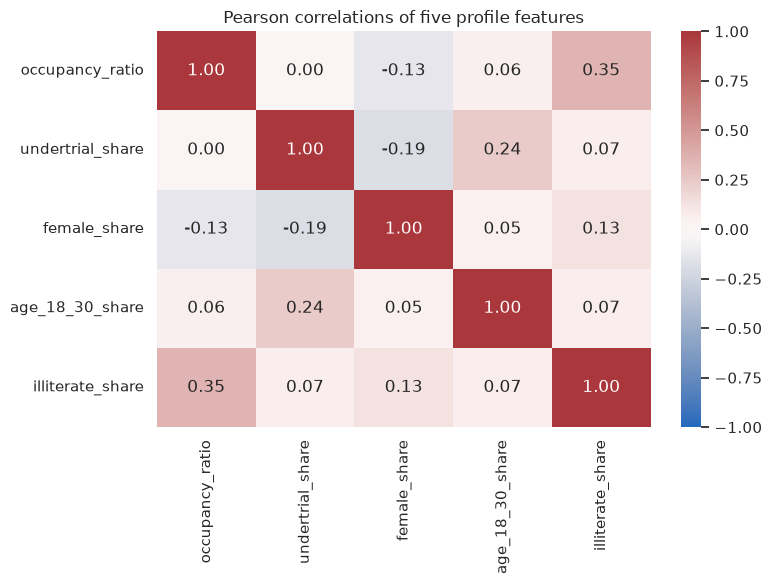

In [26]:
plt.figure(figsize=(8, 6))
sns.heatmap(profiles.drop(columns=['profile_id', 'state', 'year']).corr(), annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='vlag')
plt.title('Pearson correlations of five profile features')
save('07_heatmap', 'Heatmap', 'profile_features.csv', 'Compare all feature-pair associations on one consistent cohort.', 'The largest absolute off-diagonal Pearson correlation is 0.35432, between illiterate share and occupancy.')

**Interpretation:** The largest absolute off-diagonal Pearson correlation is 0.35432, between illiterate share and occupancy.

## Detailed occupancy values

Retain individual rounded values for 35 jurisdictions.

Source: `latest_state_snapshot.csv`.

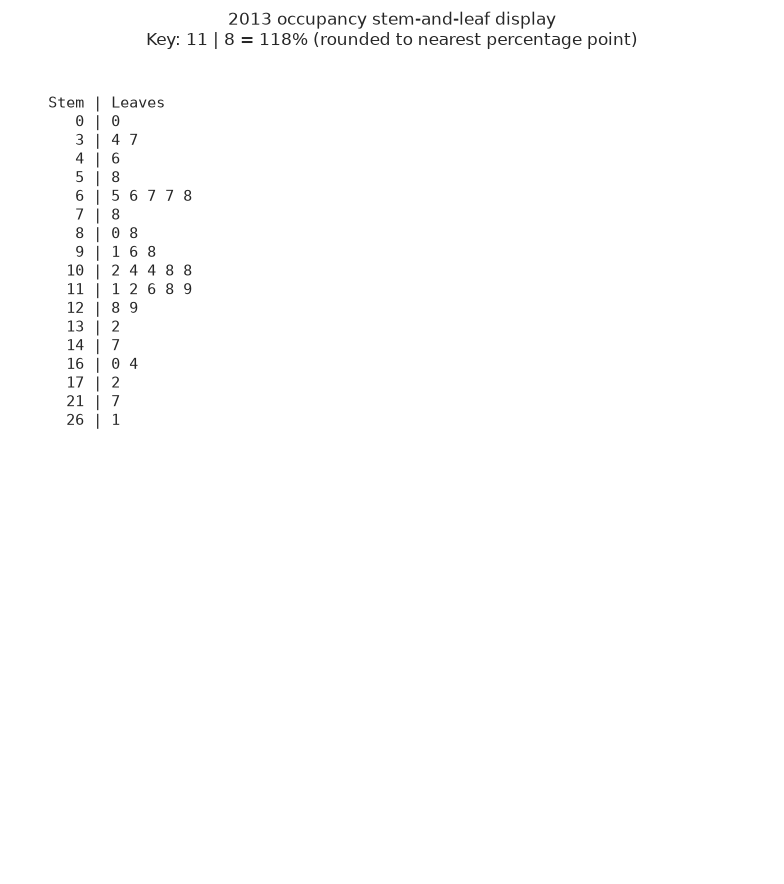

In [27]:
values = sorted((int(round(v * 100)) for v in latest.occupancy_ratio))
stems = {}
for value in values:
    stems.setdefault(value // 10, []).append(value % 10)
text = 'Stem | Leaves\n' + '\n'.join((f'{stem:>4} | ' + ' '.join(map(str, leaves)) for stem, leaves in stems.items()))
fig, ax = plt.subplots(figsize=(8, 9))
ax.axis('off')
ax.text(0.05, 0.95, text, va='top', family='monospace', fontsize=11)
ax.set_title('2013 occupancy stem-and-leaf display\nKey: 11 | 8 = 118% (rounded to nearest percentage point)')
save('10_stem_leaf', 'Stem-and-leaf', 'latest_state_snapshot.csv', 'Retain individual rounded values for 35 jurisdictions.', 'The display includes recorded zero occupancy and a rounded maximum of 261%; rounding is for this display only.')

**Interpretation:** The display includes recorded zero occupancy and a rounded maximum of 261%; rounding is for this display only.

## Save the figure catalogue

The catalogue records sources, suitability and interpretations. Plots are selected for their analytical purpose; the final assignment-specific coverage review remains documented in the report.

In [28]:
(output / "plot_catalog.json").write_text(json.dumps(records, indent=2) + "\n")
print(f"Saved {len(records)} figures and their source catalogue.")

Saved 26 figures and their source catalogue.
